# Hierarchical Clustering

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with Scikit-learn](#6-implementation-with-scikit-learn)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

**Scope note:** this notebook studies **agglomerative** (bottom-up) hierarchical clustering
with the four classic linkages (`ward`, `complete`, `average`, `single`) on Euclidean
features. The from-scratch twin in `src/models/clustering_models.py`
(`AgglomerativeClusteringScratch`) reproduces exactly that slice of
`sklearn.cluster.AgglomerativeClustering` — deliberately **not** the rest: other
distance metrics (`metric=...`), `distance_threshold`-based cutting, connectivity
constraints, and the merge-tree attributes (`children_`, `distances_`) are
sklearn/scipy-side only. Dendrogram plots in this notebook are built with
`scipy.cluster.hierarchy`, the standard tool (scipy is pinned in this repo's lockfile).

---

## 1. Introduction

### What is Hierarchical Clustering?

Every algorithm in notebooks 01–11 learned from labeled examples, and notebook 12
opened the unsupervised world with K-Means — but K-Means answers exactly one question:
"*given k, where are the groups?*" **Hierarchical clustering answers a bigger one**:
"*how do the groups nest inside each other?*" It builds a **full merge hierarchy** —
a tree that records, at every level, which clusters merged and how dissimilar they
were — and any partition is just a horizontal **cut** through that tree.

**Key characteristics:**
- **Unsupervised learning** — no target variable; structure discovered in X alone
- **Agglomerative (bottom-up)** — every point starts as its own cluster; the two
  closest clusters merge repeatedly until `n_clusters` remain (the alternative,
  *divisive*/top-down — DIANA-style — starts at one cluster and splits; rarely used)
- **The dendrogram IS the model** — one fit produces the entire ladder of merges;
  cut it at any height → that's your k. K-Means must be *re-fit* for every new k;
  hierarchical clustering is **fit once, cut anywhere**
- **No centroids, no `predict`** — a cluster is a *set of points*, not a mean vector;
  labels exist only for the rows that were fitted (the model is *transductive*)
- **Linkage-dependent geometry** — the *rule that defines "closest cluster"* is the
  hyperparameter with the most personality in this whole series (§2, §3)

**Historical Context:**
- Merges-by-similarity date to 1950s biological taxonomy (Sneath's 1957 work;
  **Sneath & Sokal's 1973 "Numerical Taxonomy"** codified the field)
- **Ward (1963)** framed merging as *minimum within-cluster variance increase* —
  the criterion behind the default `linkage='ward'` today
- **Lance & Williams (1967)** showed all classic linkages share one distance-update
  recurrence — the machinery our scratch twin implements (§5)
- Modern fast algorithms (nearest-neighbor chain, Müllner 2011) took it from
  $O(n^3)$ to $O(n^2)$ time — what sklearn runs

**Main Use Cases:**
- **Taxonomy building**: gene-expression families, phylogenetics, document/topic trees
- **Nested segmentation**: 3 macro customer segments that each contain sub-personas (§10 Example 2)
- **Choosing k *after* seeing the data**: one dendrogram, every k visible
- **Modest-n data where K-Means's convex-blob assumption is too strict**
- **A deterministic first look**: no seeds, no restarts, no local-minimum roulette

**How it works (simplified):**
1. Compute all pairwise point distances once
2. Start: n clusters (every point is its own)
3. Find the two closest clusters **under the linkage rule** and merge them
4. Update the distances from the merged cluster to all others (Lance–Williams)
5. Repeat 3–4 until `n_clusters` remain — every intermediate state was a valid partition
6. Return the labels at the requested level

**Where this notebook lands in the series:**
- Notebook 12 established the unsupervised workflow (no y, no splits, internal
  metrics); this notebook keeps the workflow and swaps the machinery: instead of
  *assigning to k centroids*, we *record every merge ever made*
- Notebook 14 (DBSCAN) is the other extreme: it refuses to merge noise at all and
  discovers k by itself — between the three of them, you pick by shape, noise, and n

### Hierarchical vs K-Means at a glance

| Aspect | Hierarchical (agglomerative) | K-Means |
|--------|------------------------------|---------|
| **Needs k upfront?** | the cut decides — but you still pass `n_clusters` | ✅ yes, before fitting |
| **What the fit produces** | the full merge tree | one flat partition + centroids |
| **Change your mind about k** | re-cut — no re-fit | re-fit from scratch |
| **Output geometry** | linkage-dependent (single → chains, ward → blobs) | convex Voronoi cells only |
| **Model artifact** | dendrogram (nested structure) | k centroid vectors |
| **New-row prediction** | ❌ none (transductive) | ✅ `.predict()` |
| **Randomness** | **none — fully deterministic** | seeding + restarts |
| **Cost** | O(n²) time & memory | O(n·k·m·i) — cheapest |

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import cut_tree, dendrogram, fcluster, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.datasets import load_iris, make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sys.path.append('../src')
from models.clustering_models import AgglomerativeClusteringScratch

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("AgglomerativeClusteringScratch imported from src/models/clustering_models.py")

Libraries imported successfully!
NumPy version: 2.5.1
Pandas version: 3.0.3
AgglomerativeClusteringScratch imported from src/models/clustering_models.py


---

## 2. Theory & Mathematics

### Core Concept: The Merge Hierarchy

Agglomerative clustering maintains one invariant and one loop:

- **Invariant**: a partition of the data into disjoint clusters, starting from
  n singletons
- **Loop**: merge the two clusters that are *closest under the linkage rule*,
  then update the distances from the new cluster to all others

Every step is **greedy and irreversible** — once two clusters merge, nothing ever
splits them apart again. The sequence of merge decisions *is* the model: stack all
~n merges on one plot, ordered by the distance at which they happened, and you have
the **dendrogram**.

### The Four Linkage Rules — four definitions of "closest pair of clusters"

Given two clusters $A$ and $B$, the linkage $d(A, B)$ decides which pair merges next:

| Linkage | Definition $d(A, B)$ | Philosophy | Failure mode |
|---|---|---|---|
| **single** | $\min_{a \in A,\, b \in B} \|a - b\|$ — the **closest** members | follows chains; can trace non-convex shapes | one sparse bridge chains two dense regions into a snake |
| **complete** | $\max_{a \in A,\, b \in B} \|a - b\|$ — the **farthest** members | keeps clusters compact; resists chaining | fragments elongated/diffuse groups |
| **average** | $\frac{1}{|A||B|}\sum_{a \in A}\sum_{b \in B} \|a - b\|$ — the **mean** over all cross pairs | the compromise; robust default when ward misbehaves | inherits a bit of both weaknesses |
| **ward** | the **increase in total within-cluster variance** the merge would cause (below) | blob-chasing; the K-Means cousin; the default | wants clusters of similar size; swallows small real groups |

Single, complete, and average operate directly on point distances. Ward is different —
it lives in the *objective*, and the objective is variance:

### Ward's Criterion

Merging clusters $A$ and $B$ (with sizes $n_A, n_B$ and means $\mu_A, \mu_B$) raises
the total within-cluster sum of squares by exactly:

$$\Delta(A, B) \;=\; \frac{n_A \, n_B}{n_A + n_B} \, \lVert \mu_A - \mu_B \rVert^2$$

**Intuition:** two big clusters with far-apart means are expensive to merge; two
tiny nearby clusters are cheap. Ward always buys the cheapest merge — the pair whose
union is most "blob-like". This is the same quantity K-Means minimizes (inertia):
**Ward's agglomeration and K-Means optimize the same objective from opposite ends**
(greedy merges up vs. centroid descent down) — on clean convex blobs they produce
near-identical partitions (demonstrated in §11).

### Lance–Williams Recurrences — never re-measure, always update

After merging $A$ and $B$, you need distances from the union $A \cup B$ to every
other cluster $K$. The naive route re-measures over all member pairs — $O(n^2)$
per merge. **Lance & Williams (1967)** showed every classic linkage instead
updates from the *old* distances $d(A,K)$, $d(B,K)$, $d(A,B)$ and the sizes:

$$d_{\text{single}}(A{\cup}B, K) = \min\big(d(A,K),\, d(B,K)\big)$$

$$d_{\text{complete}}(A{\cup}B, K) = \max\big(d(A,K),\, d(B,K)\big)$$

$$d_{\text{average}}(A{\cup}B, K) = \frac{n_A\, d(A,K) + n_B\, d(B,K)}{n_A + n_B}$$

$$d_{\text{ward}}(A{\cup}B, K)^2 = \frac{(n_A + n_K)\, d(A,K)^2 + (n_B + n_K)\, d(B,K)^2 - n_K\, d(A,B)^2}{n_A + n_B + n_K}$$

Two facts worth pinning (both verified against the twin in §5):
- **These recurrences are exact, not approximations** — for these four linkages,
  updating with Lance–Williams gives *identical* numbers to re-measuring over
  members. The trick is purely computational.
- Ward's recurrence operates on **squared** distances (that's why the $d^2$ above) —
  our twin keeps its whole Ward matrix in squared-distance space for exactly this reason.

### Reading a Dendrogram

- **Leaves** = original samples; every junction sits at the height = the linkage
  distance of that merge
- **Taller junction = later merge = more dissimilar clusters**; the root is the final merge
- **Cutting** the diagram at one height — or "at k branches" — yields the partition:
  every branch crossed by the cut line is one cluster
- **The gap is the signal**: if the last few merges jump from heights ~0.3 to ~6,
  the data had 4 (say) tight groups; the jump marks where natural structure ran out
- Heights are only comparable **within one linkage and one metric** — never read a
  ward dendrogram against an average-linkage dendrogram's axis (§9 pitfall)

**Tooling note:** scipy's `linkage` returns the tree as an $(n-1) \times 4$ matrix —
row $i$: `(idx1, idx2, merge_distance, cluster_size)`; indices $\geq n$ refer to
merges formed earlier (cluster $n + i$). sklearn's `children_` follows the same
convention, and `distances_` (with `compute_distances=True`) holds the merge
heights. `fcluster(Z, t=k, criterion='maxclust')` cuts a scipy tree into exactly k parts.

### Computational Complexity

| Phase | Time | Memory | Notes |
|---|---|---|---|
| Pairwise point distances (once) | $O(n^2 m)$ | $O(n^2)$ | the whole algorithm's floor |
| Naive merge loop (find + update per merge) | $O(n^2)$ per merge → $O(n^3)$ total | — | what the scratch twin does (honest simplification) |
| sklearn (nearest-neighbor chain, Müllner 2011) | $O(n^2)$ total | $O(n^2)$ | same tree, ~n× less scanning |

**Memory is the wall**: the $n \times n$ distance matrix caps practical n around the
tens of thousands (~50k rows ≈ 20 GB in float64). Beyond that: `sklearn.cluster.Birch`,
subsampling, or K-Means/DBSCAN — the field guide in §11 has the map.

### What Hierarchical Clustering Can Never Do

- **Un-do a merge** — greed is permanent; a bad early merge propagates upward forever
- **Label new rows** — no `predict` in sklearn or the twin; the tree belongs to the
  fitted rows (§9 has the workaround patterns)
- **Call anything noise** — every point ends up in some cluster (DBSCAN is the -1 specialist)
- **Guarantee global optimality** — the merge sequence is one greedy path through a
  combinatorial space; for a different partition you don't re-seed, you re-*link*

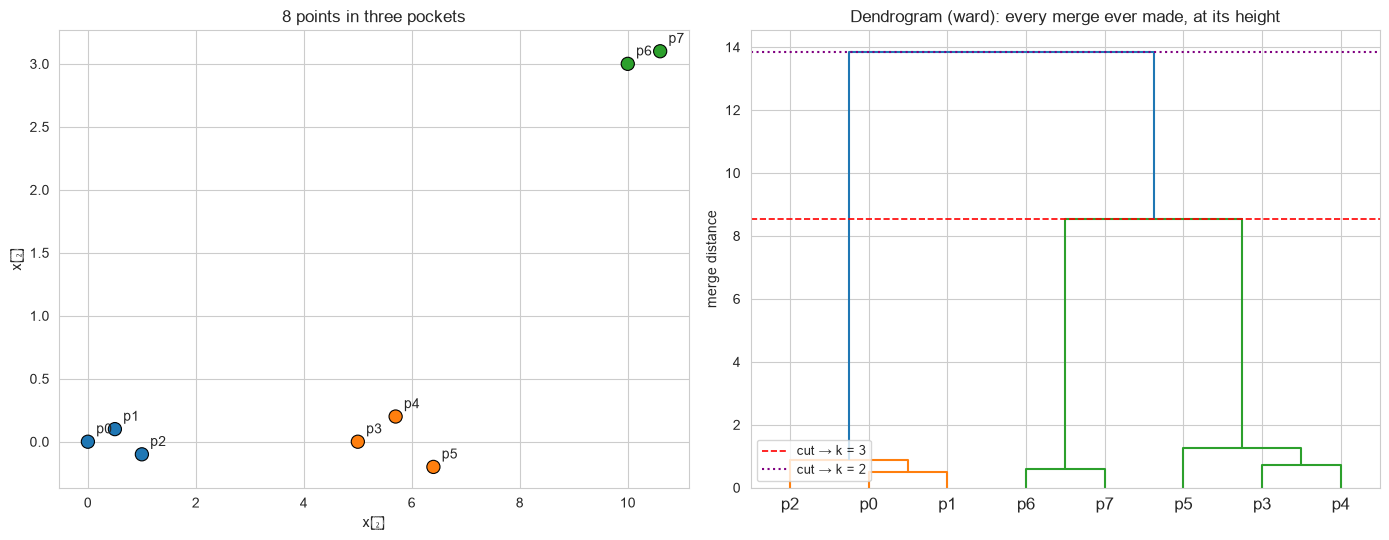

Merge ladder (from scipy's tree, last 4 merges):
  merges |   height | cluster size
       4 |    0.883 |            3
       5 |    1.261 |            3
       6 |    8.550 |            5
       7 |   13.836 |            8

💡 Read the ladder bottom-up: the last three merges happen at LARGE heights —
   those are the pocket-to-pocket joins. Everything below them (not shown) is the
   cheap within-pocket merging. A horizontal cut between the cheap zone and the
   expensive zone lands at k = 3 — exactly the three pockets.
   The k=2 cut (purple) merges the two nearest pockets into one cluster — a valid
   answer at a coarser level of the SAME tree, with no second fit involved.


In [2]:
# Visualize the core artifact: a dendrogram of a tiny dataset, and two cuts of it
# These 8 points live in three well-separated "pockets" — §5 hand-walks this exact dataset.
X_tiny = np.array([
    [0.0, 0.0], [0.5, 0.1], [1.0, -0.1],      # pocket A
    [5.0, 0.0], [5.7, 0.2], [6.4, -0.2],      # pocket B
    [10.0, 3.0], [10.6, 3.1],                 # pocket C
])

# scipy builds the merge tree (ward linkage — the sklearn default)
Z_tiny = linkage(X_tiny, method="ward")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

pocket_colors = ["#1f77b4", "#1f77b4", "#1f77b4",
                 "#ff7f0e", "#ff7f0e", "#ff7f0e",
                 "#2ca02c", "#2ca02c"]
axes[0].scatter(X_tiny[:, 0], X_tiny[:, 1], c=pocket_colors, s=90, edgecolors="k", linewidths=0.8)
for i, (x, y) in enumerate(X_tiny):
    axes[0].annotate(f"p{i}", (x, y), textcoords="offset points", xytext=(6, 6), fontsize=10)
axes[0].set_title("8 points in three pockets")
axes[0].set_xlabel("x\u2080"); axes[0].set_ylabel("x\u2081")

dendrogram(Z_tiny, ax=axes[1], labels=[f"p{i}" for i in range(len(X_tiny))])
axes[1].set_title("Dendrogram (ward): every merge ever made, at its height")
axes[1].set_ylabel("merge distance")
# horizontal cut lines for the k=2 and k=3 partitions
axes[1].axhline(y=Z_tiny[-2, 2], color="red", ls="--", lw=1.2, label="cut → k = 3")
axes[1].axhline(y=Z_tiny[-1, 2], color="purple", ls=":", lw=1.5, label="cut → k = 2")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Merge ladder (from scipy's tree, last 4 merges):")
print(f"{'merges':>8s} | {'height':>8s} | {'cluster size':>12s}")
for r in range(len(Z_tiny) - 4, len(Z_tiny)):
    print(f"{r + 1:8d} | {Z_tiny[r, 2]:8.3f} | {int(Z_tiny[r, 3]):12d}")

print("\n💡 Read the ladder bottom-up: the last three merges happen at LARGE heights —")
print("   those are the pocket-to-pocket joins. Everything below them (not shown) is the")
print("   cheap within-pocket merging. A horizontal cut between the cheap zone and the")
print("   expensive zone lands at k = 3 — exactly the three pockets.")
print("   The k=2 cut (purple) merges the two nearest pockets into one cluster — a valid")
print("   answer at a coarser level of the SAME tree, with no second fit involved.")

---

## 3. Assumptions & Requirements

Hierarchical clustering makes fewer *shape* assumptions than K-Means — but the
linkage rule quietly smuggles one in, and it is the assumption that decides whether
your partition is meaningful.

### Critical Assumptions

#### ✅ 1. **The linkage rule matches the real geometry** — THE assumption
- You are not fitting a shape; you are choosing the definition of "closest" and
  *then* the algorithm commits to it
- **single** assumes "connectedness is truth" — a chain of sparse links is a real group
- **complete/ward** assume "compactness is truth" — a group is a tight ball
- **average** assumes a bit of both
- **Violation symptom**: single linkage snakes across noise into one mega-cluster,
  or complete/ward shatter one genuinely elongated group into fragments
- **Detect**: plot the partition next to the dendrogram; read whether tall junctions
  contradict domain knowledge
- **Fix**: switch linkage — it is one argument, not a new model

#### ✅ 2. **Euclidean distance is meaningful** (sklearn's default `metric`)
- Like K-Means (nb 12): features on wildly different scales make distance a lie —
  a 0–10000-dollar feature drowns a 20–60-age feature
- **Required in practice**: `StandardScaler` before fitting (ward is *variance*-based,
  so this is doubly true for it)
- High dimensionality (~100+ dims) concentrates distances and flattens dendrograms —
  reduce with PCA (nb 15) or switch to `metric='cosine'` for embedding-style data

#### ✅ 3. **Transductive labels** — the fitted rows are the whole world
- Labels exist only for the rows you fitted; there is no `predict(new_row)` in
  sklearn or the twin — by design, not by omission
- **Fix**: see §9's workarounds (K-Means refit, nearest-member assignment)

#### ✅ 4. **Merges are irreversible and greedy**
- The first few merges happen at tiny heights and are based on local, noisy evidence —
  if they're wrong, the error compounds (the chaining cascade)
- **Detect**: compare the low-level dendrogram structure against domain sanity
- **Fix**: a more conservative linkage (complete/ward) for noisy low-level structure

#### ✅ 5. **No noise concept** — every point must join a cluster
- Outliers are absorbed somewhere (often as their own late-merging singleton branch)
- Unlike DBSCAN, there is no -1 noise label to lean on
- **Fix**: pre-filter outliers, or read very-tall, very-short dendrogram branches as
  "suspicious minority" (that's exactly what they look like in the tree)

#### ✅ 6. **Modest n** — the O(n²) pairwise matrix
- Memory, not time, is the practical limit: ~20k rows ≈ 3 GB, ~50k rows ≈ 20 GB
- **Fix**: `Birch`, subsampling, or the linear-cost algorithms (K-Means, DBSCAN)

### What Hierarchical Clustering Does NOT Require

✅ **No target variable** — unsupervised, like K-Means
✅ **No distribution assumptions** — no Gaussianity, no linearity anywhere
✅ **No k *before* the fit** — build the tree once, choose k by cutting
✅ **No seeds or restarts** — deterministic by construction (no `random_state` exists)
✅ **No equal cluster sizes** — ward mildly prefers them; single/complete/average don't care

### Data Requirements in Practice

| Requirement | Why | Fix if violated |
|---|---|---|
| **Numeric features** | Euclidean pairwise distances | encode/embed categoricals first |
| **Feature scaling** | distance (and ward variance) is scale-sensitive | `StandardScaler` / `MinMaxScaler` |
| **No missing values** | NaN breaks distance computation | impute first |
| **Modest n** | O(n²) memory | Birch / subsample / switch algorithms |
| **Same metric for all features** | one Euclidean geometry over the joint space | transform, weight, or reduce first |

### Key Differences from K-Means (notebook 12)

| Aspect | Hierarchical | K-Means |
|---|---|---|
| **Learning signal** | structure in X only | structure in X only |
| **k** | cut of the tree (post-hoc) | imposed before the fit |
| **Iteration** | n−k greedy merges, then stop | alternate assign/update until fixed point |
| **Convergence story** | none needed — the loop terminates by construction | local-minimum roulette, needs `n_init` |
| **"Overfitting" analogue** | wrong linkage; noisy low-level merges | wrong k; bad seeding |
| **Evaluation** | internal metrics + dendrogram reading | internal metrics (inertia, silhouette) |

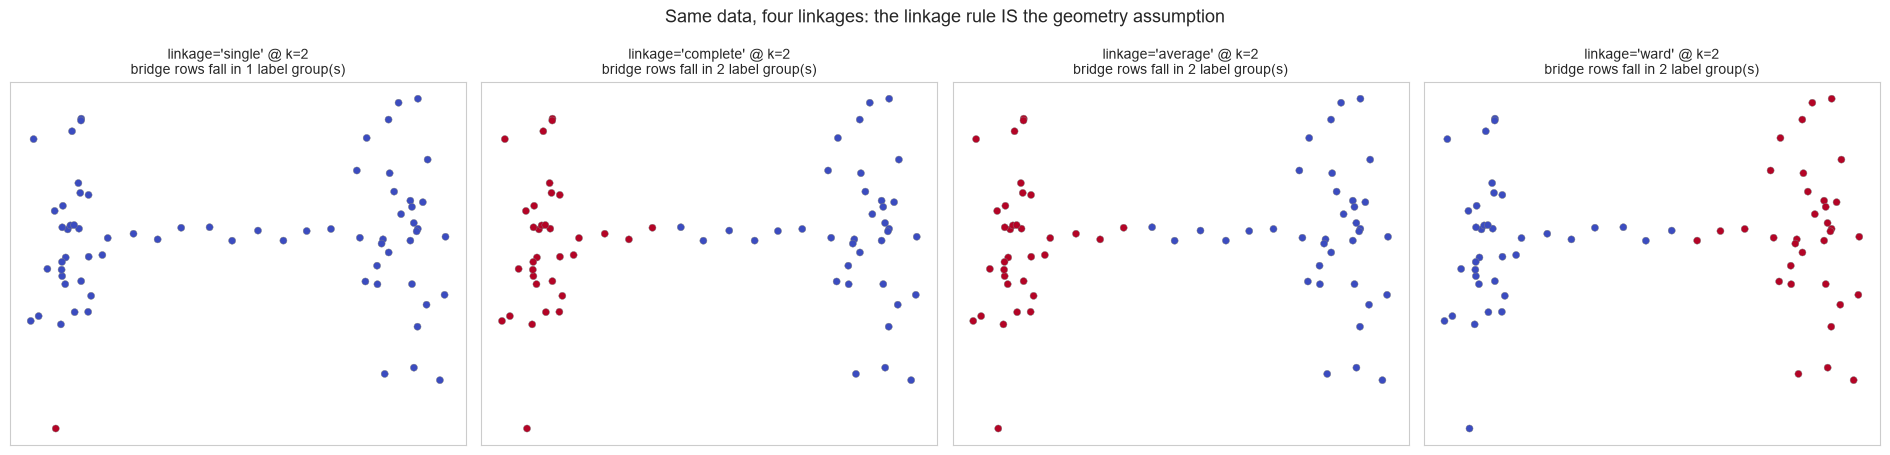

📊 How the 11 bridge rows were labeled per linkage:
  linkage=single    → 1 distinct label(s) among bridge rows
  linkage=complete  → 2 distinct label(s) among bridge rows
  linkage=average   → 2 distinct label(s) among bridge rows
  linkage=ward      → 2 distinct label(s) among bridge rows

💡 SINGLE chains the bridge into one snake — the two dense blobs become one
   cluster joined by sparse points (the classic chaining failure).
   COMPLETE refuses to: it keeps clusters compact, so the bridge gets split and
   absorbed by the blobs. ARI between the two partitions is LOW — the linkage
   choice changed the answer more than any hyperparameter in nb 01–11 could.
   Note: chaining is not *always* wrong — §5 shows it is exactly what solves rings.


In [3]:
# THE assumption in action: one dataset, four linkages, four different truths.
# Two dense blobs joined by a sparse chain of bridge points (same construction as
# the repo's own behavioral tests — tiny jitter keeps merge distances unambiguous).
rng_bridge = np.random.RandomState(11)
blob_a = rng_bridge.randn(30, 2) * 0.5 + [-4.0, 0.0]
blob_b = rng_bridge.randn(30, 2) * 0.5 + [4.0, 0.0]
xs_b = np.linspace(-3.0, 3.0, 11)
bridge = np.c_[xs_b, np.zeros_like(xs_b)] + rng_bridge.uniform(-0.05, 0.05, size=(11, 2))
X_bridge = np.vstack([blob_a, bridge, blob_b])       # bridge rows = indices 30..40

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
linkages = ["single", "complete", "average", "ward"]
bridge_row_summary = {}
for ax, lk in zip(axes, linkages):
    model = AgglomerativeClustering(n_clusters=2, linkage=lk).fit(X_bridge)
    ax.scatter(X_bridge[:, 0], X_bridge[:, 1], c=model.labels_, cmap="coolwarm",
               s=26, edgecolors="gray", linewidths=0.3)
    n_bridge_groups = len(np.unique(model.labels_[30:41]))
    bridge_row_summary[lk] = n_bridge_groups
    ax.set_title(f"linkage='{lk}' @ k=2\nbridge rows fall in {n_bridge_groups} label group(s)",
                 fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Same data, four linkages: the linkage rule IS the geometry assumption", fontsize=13)
plt.tight_layout()
plt.show()

print("📊 How the 11 bridge rows were labeled per linkage:")
for lk, g in bridge_row_summary.items():
    print(f"  linkage={lk:9s} → {g} distinct label(s) among bridge rows")
print("\n💡 SINGLE chains the bridge into one snake — the two dense blobs become one")
print("   cluster joined by sparse points (the classic chaining failure).")
print("   COMPLETE refuses to: it keeps clusters compact, so the bridge gets split and")
print("   absorbed by the blobs. ARI between the two partitions is LOW — the linkage")
print("   choice changed the answer more than any hyperparameter in nb 01–11 could.")
print("   Note: chaining is not *always* wrong — §5 shows it is exactly what solves rings.")

---

## 4. When to Use This Algorithm

### ✅ Use Hierarchical Clustering When:

1. **You want the hierarchy itself** — a taxonomy, a tree, nested structure
   - Gene-expression families, phylogenetics, document/topic ladders
   - "Do my 3 macro segments contain real sub-segments?" — one fit answers both levels (§10 Example 2)

2. **k is undecided and you want to choose it from the data**
   - Build the tree once; silhouette-vs-k and merge-height gaps (§7) advise the cut
   - K-Means forces a re-fit per candidate k; hierarchical clusters are all in the first fit

3. **Small-to-moderate n where determinism is a feature**
   - No `random_state`, no restarts, no "different answer every run" — bit-for-bit reproducible

4. **Cluster shapes are NOT nicely convex — and you can pick the right linkage**
   - Single linkage traces rings and moons (§5) where K-Means structurally cannot

5. **You need unequal cluster sizes to be legitimate**
   - K-Means's objective fragments a big cluster to balance inertia; single/complete/average don't care about sizes

6. **You want a defensible visualization for stakeholders**
   - A dendrogram *shows* the grouping logic — every merge and its cost — better than any flat partition plot

### ❌ Avoid Hierarchical Clustering When:

1. **n is large** (beyond ~20–50k rows)
   - The O(n²) matrix is a memory wall — ~50k rows ≈ 20 GB
   - **Alternative**: K-Means / MiniBatchKMeans, DBSCAN on subsampled data, or `Birch`

2. **New rows must be labeled after the fit**
   - No `predict` — the tree belongs to the fitted rows
   - **Alternative**: K-Means (native `.predict()`), or the §9 assignment patterns

3. **Outliers must be flagged, not absorbed**
   - Every point gets a cluster; outliers contaminate (esp. under single linkage)
   - **Alternative**: DBSCAN's explicit noise label (-1)

4. **You need hard guarantees on global optimality**
   - Greedy merges are one path through a combinatorial space — no restarts to hedge
   - **Alternative**: GMM with BIC selection for a probabilistic/likelihood view

5. **Categorical-heavy data without a meaningful Euclidean space**
   - One-hot + Euclidean skews distance (same trap as K-Means)
   - **Alternative**: k-modes / mixed-type methods, or embed first

6. **Runtime is the binding constraint at scale**
   - Even sklearn's O(n²) beats the twin's naive scan only relatively — K-Means is O(n·k·m·i)
   - **Alternative**: K-Means, MiniBatchKMeans

### Real-world Applications

#### 🧬 Bioinformatics (the homeland)
- Clustering gene-expression profiles into co-regulation families (dendrogram = the deliverable)
- Phylogenetic trees from distance matrices (single/average linkage on genetic dissimilarity)

#### 🛒 Retail & Marketing
- Two-level customer segmentation: macro regimes for strategy, sub-personas for campaigns (§10 Example 2)
- Assortment / SKU taxonomy from co-purchase structure

#### 📄 Text & Documents
- Building topic taxonomies from embedding vectors (`metric='cosine'`, average linkage)
- News corpus → section → sub-section trees

#### 🏙️ Geo & Social
- Neighborhood/region clustering under spatial structure (`connectivity`-constrained agglomeration — sklearn-only)
- Species/habitat classification from environmental distance matrices

> **The demo that follows** uses the Streamlit app's own `var_blobs` toy dataset
> (three regimes with very different spreads) to show the two decisions this
> algorithm actually asks of you: which linkage, and where to cut.

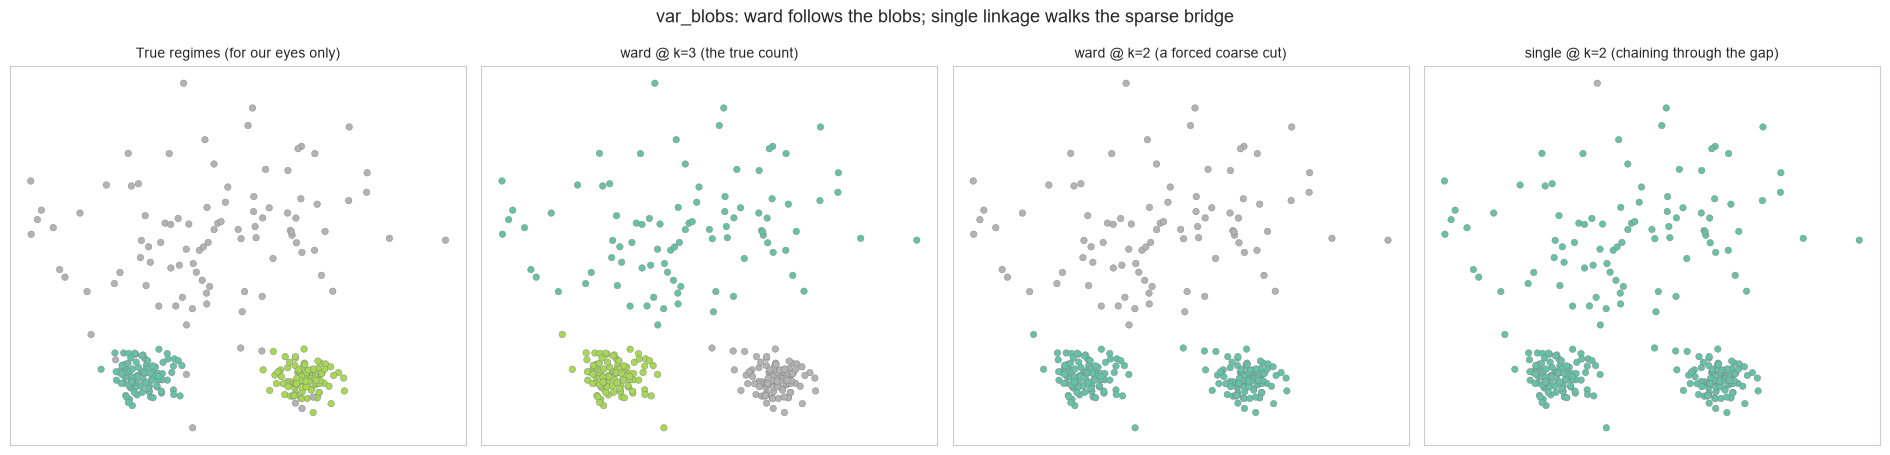

📊 ARI vs the true regimes:
  ward @ k=3 (the true count)            ARI =  0.913
  ward @ k=2 (a forced coarse cut)       ARI =  0.465
  single @ k=2 (chaining through the gap) ARI =  0.000

💡 At the TRUE count (k=3) ward recovers all three regimes — including the diffuse
   one, because nothing needs merging across its sparse edge.
   At k=2, ward must sacrifice a regime: two of the three get merged.
   Single linkage at k=2 walks THROUGH the diffuse blob's outer points and chains
   across the sparse region — the same bridge behavior as §3, now in the wild.
   One fit, many cuts: every panel above is a different slice of the same tree.


In [4]:
# The app's var_blobs dataset: three true regimes with very unequal spreads
# (exact construction from app/core/datasets.py — pin everything)
X_var, y_var_true = make_blobs(
    n_samples=300,
    centers=[(-2.0, -2.0), (2.0, -2.0), (0.0, 2.5)],
    cluster_std=[0.4, 0.4, 2.0],
    random_state=0,
)

panels = [
    ("True regimes (for our eyes only)", y_var_true, None),
    ("ward @ k=3 (the true count)", None, 3),
    ("ward @ k=2 (a forced coarse cut)", None, 2),
    ("single @ k=2 (chaining through the gap)", None, 2),
]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
ari_var = {}
for ax, (title, truth, k) in zip(axes, panels):
    if truth is not None:
        ax.scatter(X_var[:, 0], X_var[:, 1], c=truth, cmap="Set2", s=22, edgecolors="gray", linewidths=0.3)
    else:
        lk = "single" if "single" in title else "ward"
        model = AgglomerativeClustering(n_clusters=k, linkage=lk).fit(X_var)
        ax.scatter(X_var[:, 0], X_var[:, 1], c=model.labels_, cmap="Set2", s=22, edgecolors="gray", linewidths=0.3)
        ari_var[title] = adjusted_rand_score(y_var_true, model.labels_)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("var_blobs: ward follows the blobs; single linkage walks the sparse bridge", fontsize=13)
plt.tight_layout()
plt.show()

print("📊 ARI vs the true regimes:")
for title, val in ari_var.items():
    print(f"  {title:38s} ARI = {val:6.3f}")

print("\n💡 At the TRUE count (k=3) ward recovers all three regimes — including the diffuse")
print("   one, because nothing needs merging across its sparse edge.")
print("   At k=2, ward must sacrifice a regime: two of the three get merged.")
print("   Single linkage at k=2 walks THROUGH the diffuse blob's outer points and chains")
print("   across the sparse region — the same bridge behavior as §3, now in the wild.")
print("   One fit, many cuts: every panel above is a different slice of the same tree.")

---

## 5. Implementation from Scratch (NumPy)

Let's walk the from-scratch twin to make the greedy merge loop concrete — the
one-time distance matrix, the Lance–Williams updates, the tie-breaking, and the
transductive (no-predict) contract.

The from-scratch twin lives in `src/models/clustering_models.py`:
`AgglomerativeClusteringScratch`.

In [5]:
# The from-scratch implementation (already imported at the top)
print("✅ Custom agglomerative clustering twin!")
print("\nAvailable class: AgglomerativeClusteringScratch")
print("  • AgglomerativeClusteringScratch(n_clusters=2, linkage='ward')")
print("    linkage ∈ {'ward', 'complete', 'average', 'single'}")
print("  • .fit(X) → merge closest clusters until n_clusters remain")
print("  • .fit_predict(X) → fit + return the fitted rows' labels")
print("  • (deliberately NO .predict — clustering is transductive; sklearn agrees)")
print("\nFitted attributes (same names as sklearn, by design):")
print("  • labels_       (n_samples,) — cluster id 0..k-1 per fitted row")
print("  • n_clusters_   int — number of clusters found (= n_clusters)")
print("\nContract details worth knowing:")
print("  • euclidean distances only (no metric= parameter — documented simplification)")
print("  • fully deterministic: no random_state, no restarts, no ties left to chance")
print("  • validation: 1 <= n_clusters < n_samples, else ValueError with the reason")

✅ Custom agglomerative clustering twin!

Available class: AgglomerativeClusteringScratch
  • AgglomerativeClusteringScratch(n_clusters=2, linkage='ward')
    linkage ∈ {'ward', 'complete', 'average', 'single'}
  • .fit(X) → merge closest clusters until n_clusters remain
  • .fit_predict(X) → fit + return the fitted rows' labels
  • (deliberately NO .predict — clustering is transductive; sklearn agrees)

Fitted attributes (same names as sklearn, by design):
  • labels_       (n_samples,) — cluster id 0..k-1 per fitted row
  • n_clusters_   int — number of clusters found (= n_clusters)

Contract details worth knowing:
  • euclidean distances only (no metric= parameter — documented simplification)
  • fully deterministic: no random_state, no restarts, no ties left to chance
  • validation: 1 <= n_clusters < n_samples, else ValueError with the reason


AGGLOMERATIVE CLUSTERING (FROM SCRATCH)

📊 Dataset: 450 samples × 2 features, 4 true blobs (external check only)

📈 Fit results (no seeds, no restarts — deterministic by construction):
  n_clusters_       = 4
  labels_ shape     = (450,), unique ids = [0 1 2 3]
  cluster sizes     = [113 113 112 112]

🔍 Quality:
  ARI vs generating blobs (synthetic only!): 1.0000
  Silhouette (internal, no truth needed):    0.8140


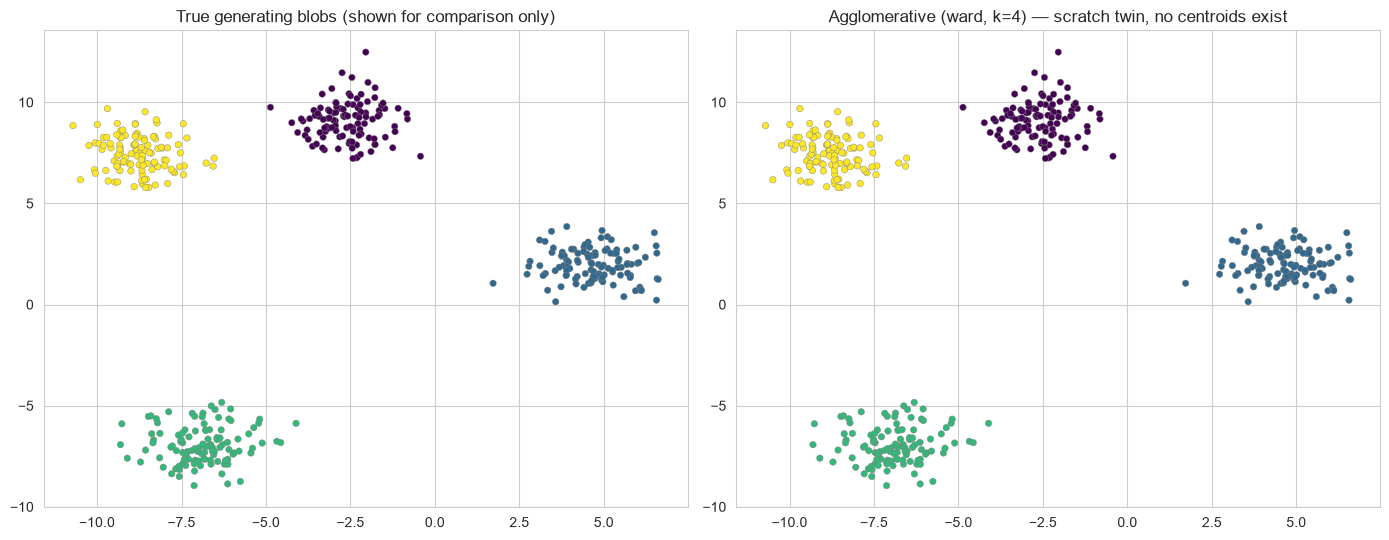

💡 Note what is ABSENT from the fit output: there are no cluster_centers_ and no
   inertia_. A cluster here is a set of points; the partition itself is the model.


In [6]:
# The same blobs dataset notebook 12 used, through the scratch twin
np.random.seed(42)
X_blobs, y_true_blobs = make_blobs(
    n_samples=450,
    centers=4,
    cluster_std=0.9,
    random_state=42,
)

print("=" * 60)
print("AGGLOMERATIVE CLUSTERING (FROM SCRATCH)")
print("=" * 60)
print(f"\n📊 Dataset: {len(X_blobs)} samples × {X_blobs.shape[1]} features, "
      f"{len(np.unique(y_true_blobs))} true blobs (external check only)")

model_scratch = AgglomerativeClusteringScratch(n_clusters=4, linkage="ward")
model_scratch.fit(X_blobs)

print("\n📈 Fit results (no seeds, no restarts — deterministic by construction):")
print(f"  n_clusters_       = {model_scratch.n_clusters_}")
print(f"  labels_ shape     = {model_scratch.labels_.shape}, "
      f"unique ids = {np.unique(model_scratch.labels_)}")
print(f"  cluster sizes     = {np.bincount(model_scratch.labels_)}")

ari_ext = adjusted_rand_score(y_true_blobs, model_scratch.labels_)
sil_int = silhouette_score(X_blobs, model_scratch.labels_)
print(f"\n🔍 Quality:")
print(f"  ARI vs generating blobs (synthetic only!): {ari_ext:.4f}")
print(f"  Silhouette (internal, no truth needed):    {sil_int:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_true_blobs, cmap="viridis",
                s=22, edgecolors="gray", linewidths=0.3)
axes[0].set_title("True generating blobs (shown for comparison only)")
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=model_scratch.labels_, cmap="viridis",
                s=22, edgecolors="gray", linewidths=0.3)
axes[1].set_title("Agglomerative (ward, k=4) — scratch twin, no centroids exist")
plt.tight_layout()
plt.show()

print("💡 Note what is ABSENT from the fit output: there are no cluster_centers_ and no")
print("   inertia_. A cluster here is a set of points; the partition itself is the model.")

### How the Scratch Version Works (a guided tour)

Read `src/models/clustering_models.py` alongside these five facts:

**1. The pairwise point-distance matrix is computed exactly once (`_squared_distances`).**
$$\lVert a - b \rVert^2 = \lVert a \rVert^2 + \lVert b \rVert^2 - 2\, a \cdot b$$
so the full $(n \times n)$ matrix is one matrix product plus two norm broadcasts, with
round-off negatives clipped to zero. After this single $O(n^2)$ pass, the fit loop
*never touches a point pair again* — everything below is bookkeeping on this matrix.

**2. Ward lives in squared-distance space; the other three get one `sqrt` up front.**
Ward's criterion is a *variance* (§2), so the twin keeps its working matrix in squared
distances where the Lance–Williams Ward recurrence is clean. For single/complete/average
it takes the elementwise square root of the point matrix once and then works in plain
distances. This is why the twin's merge choices for ward match sklearn's exactly (§6).

**3. Merging is a greedy argmin with deterministic tie-breaking.**
Each iteration masks out inactive clusters (their rows are set to `inf`), takes the
argmin over the flattened masked matrix — which resolves any exact tie by the *lowest
index pair* — and merges `a, b` into `a` (the lower representative index always wins).
Cluster sizes update, cluster `b` is deactivated, and one Lance–Williams row rebuilds
all distances from the union (next fact). No RNG anywhere in this loop — the same X
always yields the same labels, which the repo's tests pin bit-for-bit.

**4. Lance–Williams updates maintain cluster distances; nothing is re-measured.**
After merging A+B, the distance row to every other cluster K is rebuilt from
$d(A,K)$, $d(B,K)$, $d(A,B)$ and the sizes — `single` takes the `min` of the two old
rows, `complete` the `max`, `average` the size-weighted mean, and Ward the
$(n_A{+}n_K,\, n_B{+}n_K,\, -n_K)$ linear combination of **squared** distances (§2's
formula). These recurrences are *exact* for the four classic linkages — identical
numbers to re-measuring over all member pairs, just $O(n)$ per merge instead of
$O(n^2)$-ish. This is the entire reason the algorithm is affordable at all.

**5. Labels are a partition, ids are cosmetic, and there is no `predict`.**
During the loop each row tracks its *representative* (a union-find step:
`representative[representative == b] = a`). When `n_clusters` remain, `np.unique`
maps representatives to contiguous ids 0..k-1 — cluster *naming* is cosmetic, the
partition is the product. `n_clusters_` always equals `n_clusters` (no noise class
to make it smaller — that's DBSCAN's story). And fitting produces labels only for
the fitted rows: no `predict`, in sklearn as in the twin.

**What's deliberately simplified vs. sklearn** (also documented in the module docstring):
- **euclidean-only** — no `metric='l1'/'manhattan'/'cosine'/'precomputed'`
- **no `distance_threshold`** — the twin always stops at `n_clusters`, never at a height
- **no `connectivity` constraints** — every pair is a legal merge (sklearn can restrict merges to spatial neighbors)
- **no merge-tree attributes** — sklearn exposes `children_`/`distances_` (dendrogram-able); the twin returns labels only
- **naive merge loop** — one full $O(n^2)$ argmin scan per merge ($O(n^3)$ total); sklearn runs the nearest-neighbor-chain algorithm ($O(n^2)$ total, Müllner 2011)

In [7]:
# Reconstruct the twin's results by hand on the §2 tiny dataset (8 points, average linkage)
# Hand version: cluster distances are recomputed FROM MEMBERS every step (transparent, slow).
# Twin version: Lance-Williams updates (fast). §2 proved they must agree — here we watch them.

# Mean pairwise euclidean distance between two clusters' member-row lists.
def avg_link_distance(member_rows_a, member_rows_b):
    return float(np.mean([
        np.linalg.norm(X_tiny[i] - X_tiny[j])
        for i in member_rows_a for j in member_rows_b
    ]))

clusters = [[i] for i in range(len(X_tiny))]     # member-index lists, one per cluster
merge_log = []
partitions = {}                                   # remaining-cluster-count → label vector

while len(clusters) > 1:
    best = None
    for i in range(len(clusters)):
        for j in range(i + 1, len(clusters)):
            d = avg_link_distance(clusters[i], clusters[j])
            if best is None or d < best[0]:       # strict '<' = first pair wins ties
                best = (d, i, j)
    d, i, j = best
    clusters[i] = clusters[i] + clusters[j]
    del clusters[j]
    merge_log.append((len(merge_log) + 1, tuple(clusters[i]), d))

    if len(clusters) in (4, 3, 2):
        labels_hand = np.empty(len(X_tiny), dtype=int)
        for cid, members in enumerate(clusters):
            labels_hand[members] = cid
        partitions[len(clusters)] = labels_hand

print("Hand-walked merge table (average linkage):")
print(f"{'step':>4s} | {'members of the new cluster':>40s} | {'height':>8s}")
for step, members, d in merge_log:
    print(f"{step:4d} | {str(members):>40s} | {d:8.3f}")

# Cross-check #1 — scipy's independent implementation must produce the SAME heights
Z_hand_check = linkage(X_tiny, method="average")
hand_heights = np.array([d for _, _, d in merge_log])
scipy_heights = Z_hand_check[:, 2]
print(f"\n🤝 merge heights: hand-walk vs scipy → allclose = "
      f"{np.allclose(hand_heights, scipy_heights)}")

# Cross-check #2 — the twin (Lance-Williams) must produce the SAME partitions
print("\n🤝 twin (Lance-Williams) vs hand-walk partitions:")
for k in (4, 3, 2):
    twin = AgglomerativeClusteringScratch(n_clusters=k, linkage="average").fit(X_tiny)
    ari_k = adjusted_rand_score(partitions[k], twin.labels_)
    print(f"   k = {k}: ARI = {ari_k:.4f}")

print("\n💡 Three independent routes to one answer:")
print("   • the hand-walk re-measures member distances every step (slow, transparent)")
print("   • scipy maintains its own tree internally (production implementation)")
print("   • the twin updates Lance-Williams rows (fast, opaque)")
print("   Same merges, same heights, same partitions — the recurrences are EXACT (§2, fact 4).")

Hand-walked merge table (average linkage):
step |               members of the new cluster |   height
   1 |                                   (0, 1) |    0.510
   2 |                                   (6, 7) |    0.608
   3 |                                   (3, 4) |    0.728
   4 |                                (0, 1, 2) |    0.772
   5 |                                (3, 4, 5) |    1.110
   6 |                       (0, 1, 2, 3, 4, 5) |    5.203
   7 |                 (0, 1, 2, 3, 4, 5, 6, 7) |    7.901

🤝 merge heights: hand-walk vs scipy → allclose = True

🤝 twin (Lance-Williams) vs hand-walk partitions:
   k = 4: ARI = 1.0000
   k = 3: ARI = 1.0000
   k = 2: ARI = 1.0000

💡 Three independent routes to one answer:
   • the hand-walk re-measures member distances every step (slow, transparent)
   • scipy maintains its own tree internally (production implementation)
   • the twin updates Lance-Williams rows (fast, opaque)
   Same merges, same heights, same partitions — the recurre

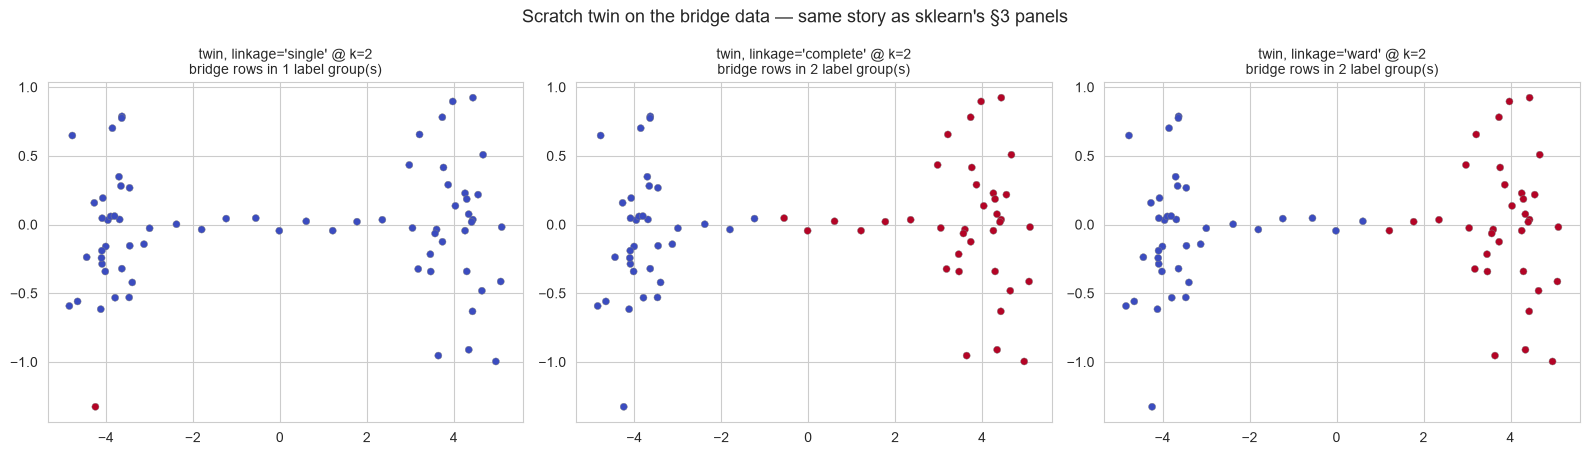

📊 Bridge-row grouping (twin):
  linkage=single    → 1 distinct label(s) among bridge rows
  linkage=complete  → 2 distinct label(s) among bridge rows
  linkage=ward      → 2 distinct label(s) among bridge rows

🤝 twin vs sklearn, single linkage, ARI = 1.0000

💡 The twin — Lance-Williams rows and all — reproduces sklearn's partition exactly.
   The behavior lives in the MERGE RULE, not in the implementation details.


In [8]:
# The §3 bridge experiment, now through the scratch twin — the behavior must match sklearn's
rng_bridge2 = np.random.RandomState(11)
blob_a2 = rng_bridge2.randn(30, 2) * 0.5 + [-4.0, 0.0]
blob_b2 = rng_bridge2.randn(30, 2) * 0.5 + [4.0, 0.0]
xs_b2 = np.linspace(-3.0, 3.0, 11)
bridge2 = np.c_[xs_b2, np.zeros_like(xs_b2)] + rng_bridge2.uniform(-0.05, 0.05, size=(11, 2))
X_bridge2 = np.vstack([blob_a2, bridge2, blob_b2])   # bridge rows = indices 30..40

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
twin_rows = []
for ax, lk in zip(axes, ["single", "complete", "ward"]):
    twin_b = AgglomerativeClusteringScratch(n_clusters=2, linkage=lk).fit(X_bridge2)
    ax.scatter(X_bridge2[:, 0], X_bridge2[:, 1], c=twin_b.labels_, cmap="coolwarm",
               s=26, edgecolors="gray", linewidths=0.3)
    n_bridge = len(np.unique(twin_b.labels_[30:41]))
    twin_rows.append((lk, n_bridge))
    ax.set_title(f"twin, linkage='{lk}' @ k=2\nbridge rows in {n_bridge} label group(s)", fontsize=10)

plt.suptitle("Scratch twin on the bridge data — same story as sklearn's §3 panels", fontsize=13)
plt.tight_layout()
plt.show()

print("📊 Bridge-row grouping (twin):")
for lk, n in twin_rows:
    print(f"  linkage={lk:9s} → {n} distinct label(s) among bridge rows")

# sklearn's own run on the identical data for the formal agreement check
sk_single = AgglomerativeClustering(n_clusters=2, linkage="single").fit(X_bridge2)
twin_single = AgglomerativeClusteringScratch(n_clusters=2, linkage="single").fit(X_bridge2)
print(f"\n🤝 twin vs sklearn, single linkage, ARI = "
      f"{adjusted_rand_score(twin_single.labels_, sk_single.labels_):.4f}")

print("\n💡 The twin — Lance-Williams rows and all — reproduces sklearn's partition exactly.")
print("   The behavior lives in the MERGE RULE, not in the implementation details.")

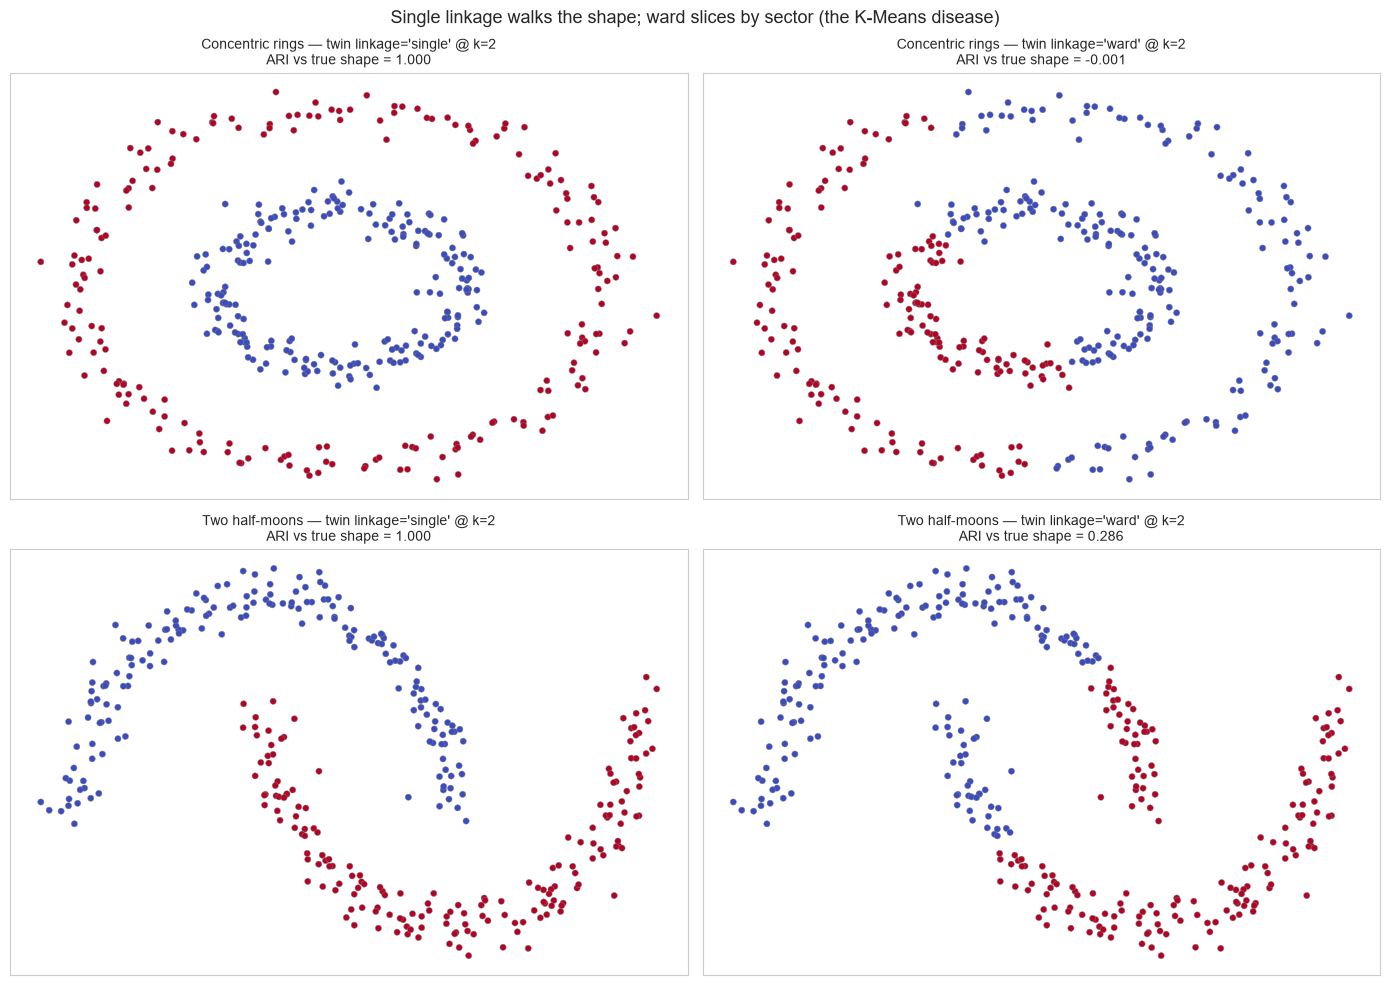

📊 ARI vs the true generating shape:
  Concentric rings   linkage=single    →  1.000
  Concentric rings   linkage=ward      → -0.001
  Two half-moons     linkage=single    →  1.000
  Two half-moons     linkage=ward      →  0.286

💡 Single linkage chains AROUND the ring — its infamous chaining is exactly the
   property that follows density-connected structure, so it solves the rings/moons
   family K-Means (and ward, its close cousin) cannot express.
   The SAME property destroyed the §3 bridge. Chaining is not a bug — it is a
   geometry choice: connectedness (single) vs compactness (complete/ward).
   ⚠️ The noise here is deliberately small: under heavier noise, single linkage's
   low-level merges start chaining across gaps — §9's first debugging recipe.


In [9]:
# The flip side of chaining: single linkage is the rule that can trace NON-convex shapes
X_rings, y_rings = make_circles(n_samples=400, factor=0.45, noise=0.06, random_state=42)
X_moons, y_moons = make_moons(n_samples=350, noise=0.07, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
geometry_results = {}
for row, (X_sh, y_sh, name) in enumerate([
    (X_rings, y_rings, "Concentric rings"),
    (X_moons, y_moons, "Two half-moons"),
]):
    for col, lk in enumerate(["single", "ward"]):
        twin_g = AgglomerativeClusteringScratch(n_clusters=2, linkage=lk).fit(X_sh)
        ari_g = adjusted_rand_score(y_sh, twin_g.labels_)
        geometry_results[(name, lk)] = ari_g
        ax = axes[row, col]
        ax.scatter(X_sh[:, 0], X_sh[:, 1], c=twin_g.labels_, cmap="coolwarm",
                   s=20, edgecolors="gray", linewidths=0.3)
        ax.set_title(f"{name} — twin linkage='{lk}' @ k=2\nARI vs true shape = {ari_g:.3f}",
                     fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Single linkage walks the shape; ward slices by sector (the K-Means disease)", fontsize=13)
plt.tight_layout()
plt.show()

print("📊 ARI vs the true generating shape:")
for (name, lk), val in geometry_results.items():
    print(f"  {name:18s} linkage={lk:9s} → {val:6.3f}")

print("\n💡 Single linkage chains AROUND the ring — its infamous chaining is exactly the")
print("   property that follows density-connected structure, so it solves the rings/moons")
print("   family K-Means (and ward, its close cousin) cannot express.")
print("   The SAME property destroyed the §3 bridge. Chaining is not a bug — it is a")
print("   geometry choice: connectedness (single) vs compactness (complete/ward).")
print("   ⚠️ The noise here is deliberately small: under heavier noise, single linkage's")
print("   low-level merges start chaining across gaps — §9's first debugging recipe.")

---

## 6. Implementation with Scikit-learn

Now the industry implementation on the same data — plus the merge-tree machinery the
twin doesn't expose (`children_`, `distances_`) and the dendrogram tooling from scipy.

Facts verified in this environment (scikit-learn 1.9) worth pinning before we fit:
- The estimator is **fully deterministic — there is no `random_state`**. Reproducibility is free.
- The metric parameter is **`metric=`** (values: `'euclidean'`, `'l1'`, `'l2'`, `'manhattan'`, `'cosine'`, `'precomputed'`). The old `affinity=` spelling is **gone from the API**; tutorials that use it raise `InvalidParameterError`. With `linkage='ward'`, only euclidean/l2 metrics are accepted.
- Full signature (1.9): `AgglomerativeClustering(n_clusters=2, *, metric='euclidean', memory=None, connectivity=None, compute_full_tree='auto', linkage='ward', distance_threshold=None, compute_distances=False)`
- Fitted attributes beyond the twin's `labels_`/`n_clusters_`: **`children_`** (the merge tree, `(n−1, 2)`), **`distances_`** (merge heights, when `compute_distances=True` or `distance_threshold` is set), `n_leaves_`, `n_connected_components_`, `n_features_in_`
- Still **no `predict`** — sklearn's agglomerative clustering is transductive, like the twin

SCIKIT-LEARN AGGLOMERATIVE CLUSTERING (ward, k=4)

📊 Fit results:
  labels_ unique ids : [0 1 2 3]
  cluster sizes      : [113 112 113 112]
  n_clusters_        : 4
  n_leaves_          : 450
  n_connected_components_ : 1
  n_features_in_     : 2

🌳 children_ shape: (449, 2) — one row per merge:
  (columns = the two cluster-ids being merged; ids < n are original sample rows,
   ids >= n refer to clusters formed earlier — convention n + i for merge i)
  first 3 merges : [[ 14 382]
 [300 365]
 [155 325]]
  last merge     : [893 897]

🔍 External check on this synthetic dataset:
  ARI vs generating blobs: 1.0000
  Silhouette             : 0.8140


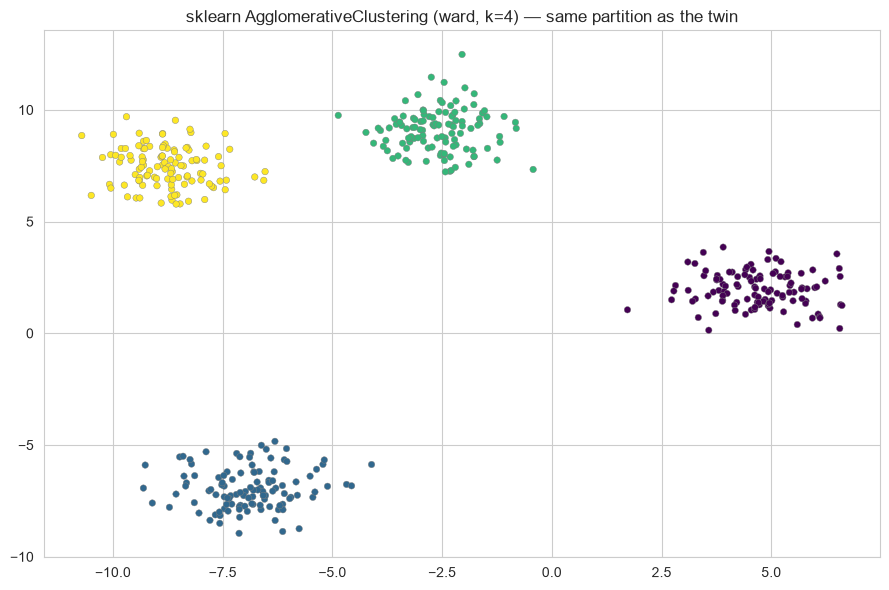

💡 Same partition as §5's twin on this data (formal check coming in two cells).
   sklearn's fit is C/OpenMP plus the O(n²) nearest-neighbor-chain algorithm —
   same greedy math, much less scanning than the twin's naive loop.


In [10]:
# The §5 blobs data through sklearn — then inspect the merge tree the twin doesn't expose
agglom_sk = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_blobs)

print("=" * 60)
print("SCIKIT-LEARN AGGLOMERATIVE CLUSTERING (ward, k=4)")
print("=" * 60)
print(f"\n📊 Fit results:")
print(f"  labels_ unique ids : {np.unique(agglom_sk.labels_)}")
print(f"  cluster sizes      : {np.bincount(agglom_sk.labels_)}")
print(f"  n_clusters_        : {agglom_sk.n_clusters_}")
print(f"  n_leaves_          : {agglom_sk.n_leaves_}")
print(f"  n_connected_components_ : {agglom_sk.n_connected_components_}")
print(f"  n_features_in_     : {agglom_sk.n_features_in_}")

print(f"\n🌳 children_ shape: {agglom_sk.children_.shape} — one row per merge:")
print("  (columns = the two cluster-ids being merged; ids < n are original sample rows,")
print("   ids >= n refer to clusters formed earlier — convention n + i for merge i)")
print("  first 3 merges :", agglom_sk.children_[:3])
print("  last merge     :", agglom_sk.children_[-1])

print(f"\n🔍 External check on this synthetic dataset:")
print(f"  ARI vs generating blobs: {adjusted_rand_score(y_true_blobs, agglom_sk.labels_):.4f}")
print(f"  Silhouette             : {silhouette_score(X_blobs, agglom_sk.labels_):.4f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=agglom_sk.labels_, cmap="viridis",
           s=22, edgecolors="gray", linewidths=0.3)
ax.set_title("sklearn AgglomerativeClustering (ward, k=4) — same partition as the twin")
plt.tight_layout()
plt.show()

print("💡 Same partition as §5's twin on this data (formal check coming in two cells).")
print("   sklearn's fit is C/OpenMP plus the O(n²) nearest-neighbor-chain algorithm —")
print("   same greedy math, much less scanning than the twin's naive loop.")

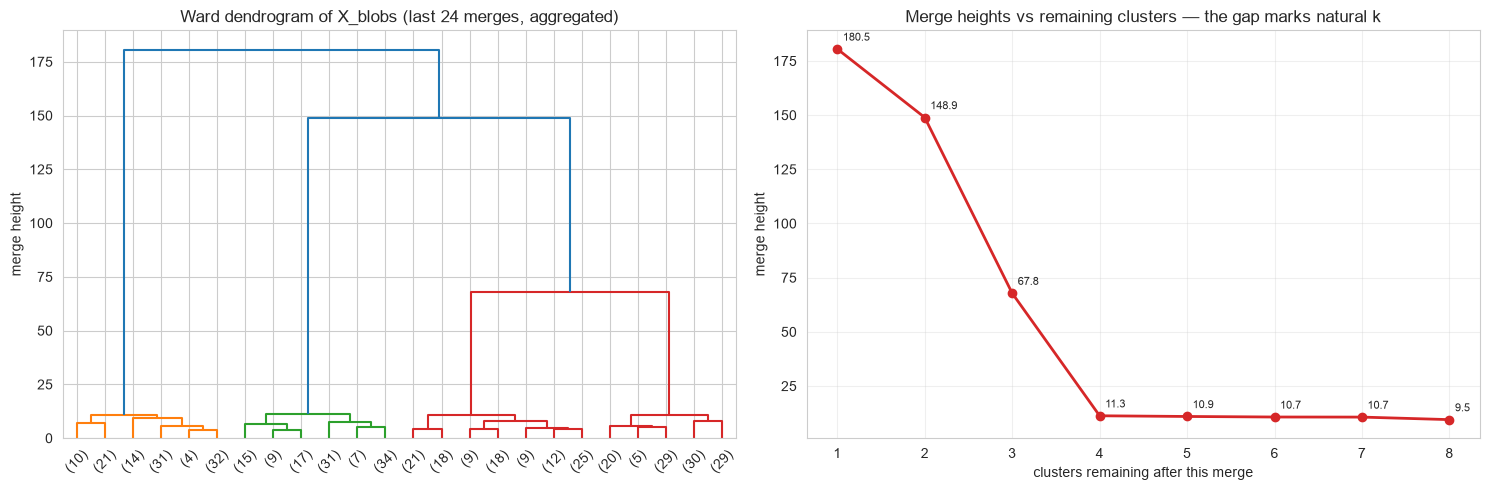

📊 The tail of the merge ladder:
 merge # |     height | clusters left
     442 |      9.484 |             8
     443 |     10.654 |             7
     444 |     10.690 |             6
     445 |     10.939 |             5
     446 |     11.258 |             4
     447 |     67.811 |             3
     448 |    148.898 |             2
     449 |    180.513 |             1

🤝 fcluster(maxclust, k=3) vs sklearn(ward, k=3): ARI = 1.0000
🤝 cut_tree(n_clusters=3)   vs sklearn(ward, k=3): ARI = 1.0000

💡 The right panel is the dendrogram turned into a decision chart: heights stay
   low while natural clusters absorb their points, then JUMP when the merges
   must cross real structure. The jump's location = the k the tree prefers.
   scipy and sklearn build the same tree — cuts agree (ARI = 1.0).


In [11]:
# Dendrograms: scipy builds the tree; fcluster/cut_tree cut it; sklearn must agree
Z_blob = linkage(X_blobs, method="ward")     # scipy's tree from the SAME observations

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# left: the last p merges, aggregated (readable even at n=450)
dendrogram(Z_blob, ax=axes[0], truncate_mode="lastp", p=24, show_leaf_counts=True)
axes[0].set_title("Ward dendrogram of X_blobs (last 24 merges, aggregated)")
axes[0].set_ylabel("merge height")

# right: merge heights for the tail — the gap is the natural cut point
tail_h = Z_blob[-8:, 2]
tail_k = np.arange(len(tail_h), 0, -1)   # clusters remaining after each of the last 8 merges
axes[1].plot(tail_k, tail_h, "o-", color="#d62728", lw=2)
axes[1].set_xlabel("clusters remaining after this merge")
axes[1].set_ylabel("merge height")
axes[1].set_title("Merge heights vs remaining clusters — the gap marks natural k")
axes[1].grid(True, alpha=0.3)
for k_val, h_val in zip(tail_k, tail_h):
    axes[1].annotate(f"{h_val:.1f}", (k_val, h_val), textcoords="offset points",
                     xytext=(4, 6), fontsize=8)

plt.tight_layout()
plt.show()

print("📊 The tail of the merge ladder:")
print(f"{'merge #':>8s} | {'height':>10s} | {'clusters left':>13s}")
for i, (k_val, h_val) in enumerate(zip(tail_k, tail_h)):
    print(f"{len(Z_blob) - 8 + i + 1:8d} | {h_val:10.3f} | {k_val:13d}")

# Cut the scipy tree two ways — then verify both against sklearn's own partition
labels_fclust = fcluster(Z_blob, t=3, criterion="maxclust")          # exactly 3 clusters
labels_cuttree = cut_tree(Z_blob, n_clusters=3).ravel()             # the alternative API
sk_ward3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_blobs)

print(f"\n🤝 fcluster(maxclust, k=3) vs sklearn(ward, k=3): "
      f"ARI = {adjusted_rand_score(labels_fclust, sk_ward3.labels_):.4f}")
print(f"🤝 cut_tree(n_clusters=3)   vs sklearn(ward, k=3): "
      f"ARI = {adjusted_rand_score(labels_cuttree, sk_ward3.labels_):.4f}")

print("\n💡 The right panel is the dendrogram turned into a decision chart: heights stay")
print("   low while natural clusters absorb their points, then JUMP when the merges")
print("   must cross real structure. The jump's location = the k the tree prefers.")
print("   scipy and sklearn build the same tree — cuts agree (ARI = 1.0).")

In [12]:
# DUAL ENGINE: the scratch twin vs sklearn on the same data, all four linkages
print("=" * 68)
print("DUAL ENGINE: AGGLOMERATIVECLUSTERINGSCRATCH vs SKLEARN (X_blobs, k=4)")
print("=" * 68)
print(f"\n| linkage  | ARI (twin vs sklearn) | twin fit (s) | sklearn fit (s) |")
print(f"|----------|-----------------------|--------------|-----------------|")
for lk in ["ward", "complete", "average", "single"]:
    t0 = time.time()
    twin_d = AgglomerativeClusteringScratch(n_clusters=4, linkage=lk).fit(X_blobs)
    t_twin = time.time() - t0
    t0 = time.time()
    sk_d = AgglomerativeClustering(n_clusters=4, linkage=lk).fit(X_blobs)
    t_sk = time.time() - t0
    ari_d = adjusted_rand_score(twin_d.labels_, sk_d.labels_)
    print(f"| {lk:9s}| {ari_d:21.4f} | {t_twin:12.3f} | {t_sk:15.3f} |")

print("\n💡 Read the ARI column as the whole story: the twin's greedy argmin loop and")
print("   sklearn's nearest-neighbor-chain make the SAME merges here — agreement is")
print("   exact (ARI = 1.0), which is exactly what the repo's behavioral tests pin for")
print("   all four linkages. Cluster-id numbers may differ; ARI ignores that.")
print("   The time columns show why the twin is for READING and sklearn is for RUNNING:")
print("   vectorized C + nn-chain vs a Python loop with an O(n²) scan per merge.")

DUAL ENGINE: AGGLOMERATIVECLUSTERINGSCRATCH vs SKLEARN (X_blobs, k=4)

| linkage  | ARI (twin vs sklearn) | twin fit (s) | sklearn fit (s) |
|----------|-----------------------|--------------|-----------------|
| ward     |                1.0000 |        0.230 |           0.002 |
| complete |                1.0000 |        0.250 |           0.002 |
| average  |                1.0000 |        0.216 |           0.002 |
| single   |                1.0000 |        0.210 |           0.002 |

💡 Read the ARI column as the whole story: the twin's greedy argmin loop and
   sklearn's nearest-neighbor-chain make the SAME merges here — agreement is
   exact (ARI = 1.0), which is exactly what the repo's behavioral tests pin for
   all four linkages. Cluster-id numbers may differ; ARI ignores that.
   The time columns show why the twin is for READING and sklearn is for RUNNING:
   vectorized C + nn-chain vs a Python loop with an O(n²) scan per merge.


In [13]:
# sklearn-only machinery the twin deliberately skips
print("=" * 66)
print("SKLEARN-ONLY EXTRAS (twin simplifications, made concrete)")
print("=" * 66)

# --- 1. distance_threshold: let the TREE decide k instead of you ---
# Read the gap from the tree (§2/§6): midpoint between the last cheap merge
# (heights[-4]) and the first expensive one (heights[-3]).
thr_auto = float(0.5 * (Z_blob[-4, 2] + Z_blob[-3, 2]))
thr_model = AgglomerativeClustering(
    n_clusters=None, distance_threshold=thr_auto, compute_full_tree=True,
    linkage="ward",
).fit(X_blobs)
print(f"\n1️⃣ distance_threshold={thr_auto:.2f} (read from the tree's own gap):")
print(f"   n_clusters_ found by the height cut = {thr_model.n_clusters_}")

# --- 2. metric=: non-euclidean geometries (ward refuses everything else) ---
cos_model = AgglomerativeClustering(
    n_clusters=4, linkage="average", metric="cosine",
).fit(X_blobs)
print(f"\n2️⃣ metric='cosine', linkage='average': labels "
      f"{np.unique(cos_model.labels_)} — fits fine")
print("   (cosine's home turf is embedding/text data; blobs are radial-geometric)")
l1_model = AgglomerativeClustering(
    n_clusters=4, linkage="complete", metric="manhattan",
).fit(X_blobs)
print(f"   metric='manhattan', linkage='complete' also works: ids "
      f"{np.unique(l1_model.labels_)}")

# --- 3. compute_distances=True: merge heights without a threshold cut ---
dist_model = AgglomerativeClustering(
    n_clusters=4, linkage="ward", compute_distances=True,
).fit(X_blobs)
print(f"\n3️⃣ compute_distances=True → distances_ shape = {dist_model.distances_.shape}")
print(f"   last 3 merge heights: {np.round(dist_model.distances_[-3:], 3)}")
print(f"   (same values as scipy's Z_blob[:, 2] tail — one tree, two access APIs)")

print("\n💡 What the twin does NOT cover, in one look:")
print("   • threshold cutting by height (needs the tree, not just labels)")
print("   • non-euclidean metrics — try metric='cosine' on text embeddings")
print("   • connectivity-constrained merges (spatial/structured data)")
print("   • children_/distances_ — the twin gives labels; the tree comes from scipy/sklearn")

SKLEARN-ONLY EXTRAS (twin simplifications, made concrete)

1️⃣ distance_threshold=39.53 (read from the tree's own gap):
   n_clusters_ found by the height cut = 4

2️⃣ metric='cosine', linkage='average': labels [0 1 2 3] — fits fine
   (cosine's home turf is embedding/text data; blobs are radial-geometric)
   metric='manhattan', linkage='complete' also works: ids [0 1 2 3]

3️⃣ compute_distances=True → distances_ shape = (449,)
   last 3 merge heights: [ 67.811 148.898 180.513]
   (same values as scipy's Z_blob[:, 2] tail — one tree, two access APIs)

💡 What the twin does NOT cover, in one look:
   • threshold cutting by height (needs the tree, not just labels)
   • non-euclidean metrics — try metric='cosine' on text embeddings
   • connectivity-constrained merges (spatial/structured data)
   • children_/distances_ — the twin gives labels; the tree comes from scipy/sklearn


---

## 7. Hyperparameter Tuning (Choosing the Cut)

**There is no accuracy and no GridSearchCV in this section** — same rule as notebook 12:
unsupervised models are scored with internal metrics. Hierarchical clustering has
exactly two tuning decisions, and both are made *around* the fit rather than inside it:

1. **The linkage** — which geometry to trust (§3's assumption made concrete)
2. **The cut** — how many clusters the tree should hand you:
   - **Silhouette sweep**: mean silhouette per candidate k; peak = sweet spot
   - **Merge-height gaps**: the jump in the dendrogram's tail marks natural k
   - **`distance_threshold`**: cut by height when you have a dissimilarity budget
   - **Domain sense**: the count a stakeholder can act on (§10)

We keep notebook 12's blobs dataset (4 natural clusters) and the app's `var_blobs`
(3 regimes with unequal spreads) — one clean geometry, one messy one.

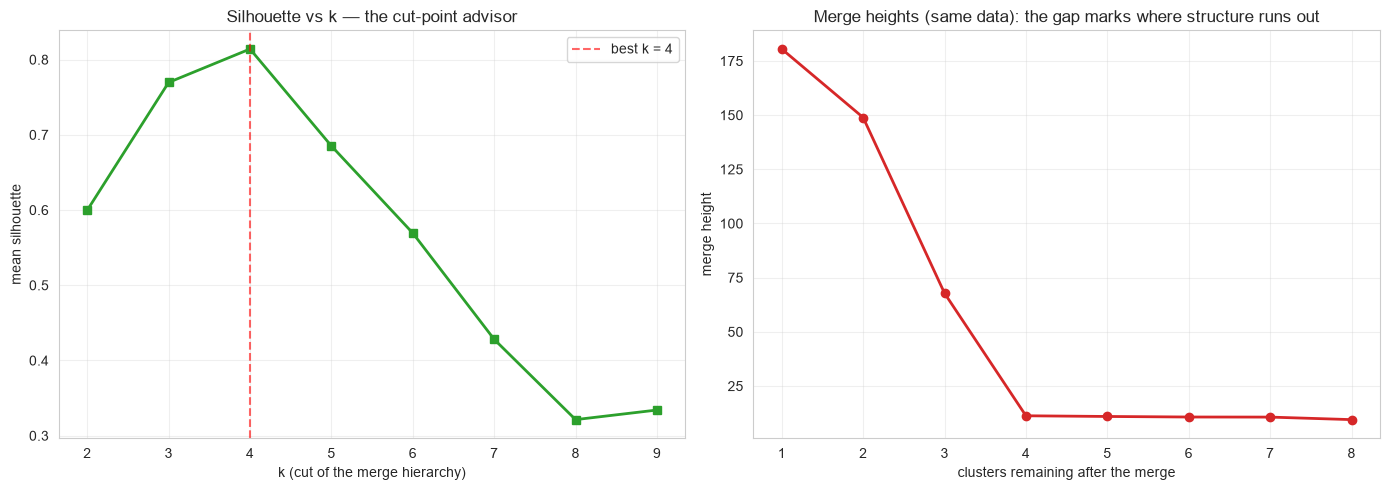

📊 Silhouette by k (ward on X_blobs):
  k=2 | silhouette 0.5997
  k=3 | silhouette 0.7696
  k=4 | silhouette 0.8140  👈 peak
  k=5 | silhouette 0.6851
  k=6 | silhouette 0.5693
  k=7 | silhouette 0.4281
  k=8 | silhouette 0.3213
  k=9 | silhouette 0.3341

💡 The silhouette panel and the merge-height panel are two readings of ONE tree:
   the silhouette peak and the height jump should land near the same k. When they
   disagree, trust the height gap for 'how many real groups' and the silhouette
   for 'which cut is cleanest' — then let domain sense arbitrate (§10).


In [14]:
# Choosing k on clean blobs: silhouette sweep + the merge-height view, side by side
ks_hc = list(range(2, 10))
sils_hc = []
for k_hc in ks_hc:
    ag_k = AgglomerativeClustering(n_clusters=k_hc, linkage="ward").fit(X_blobs)
    sils_hc.append(silhouette_score(X_blobs, ag_k.labels_))

best_k_hc = ks_hc[int(np.argmax(sils_hc))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ks_hc, sils_hc, "s-", lw=2, color="#2ca02c")
axes[0].axvline(x=best_k_hc, color="red", ls="--", alpha=0.6, label=f"best k = {best_k_hc}")
axes[0].set_xlabel("k (cut of the merge hierarchy)")
axes[0].set_ylabel("mean silhouette")
axes[0].set_title("Silhouette vs k — the cut-point advisor")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(tail_k, tail_h, "o-", lw=2, color="#d62728")
axes[1].set_xlabel("clusters remaining after the merge")
axes[1].set_ylabel("merge height")
axes[1].set_title("Merge heights (same data): the gap marks where structure runs out")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("📊 Silhouette by k (ward on X_blobs):")
for k_hc, s_hc in zip(ks_hc, sils_hc):
    marker = "  👈 peak" if k_hc == best_k_hc else ""
    print(f"  k={k_hc} | silhouette {s_hc:.4f}{marker}")

print(f"\n💡 The silhouette panel and the merge-height panel are two readings of ONE tree:")
print("   the silhouette peak and the height jump should land near the same k. When they")
print("   disagree, trust the height gap for 'how many real groups' and the silhouette")
print("   for 'which cut is cleanest' — then let domain sense arbitrate (§10).")

Mean silhouette (higher = better):
k             2      3      4      5      6
linkage                                    
average   0.508  0.462  0.657  0.642  0.646
complete  0.348  0.460  0.439  0.642  0.639
single    0.474  0.318  0.269  0.268  0.358
ward      0.508  0.644  0.657  0.656  0.655

ARI vs the three true regimes (1.0 = perfect):
k             2      3      4      5      6
linkage                                    
average   0.465  0.358  0.802  0.797  0.775
complete  0.122  0.359  0.347  0.790  0.771
single    0.000  0.000  0.000  0.000  0.542
ward      0.465  0.913  0.802  0.779  0.759


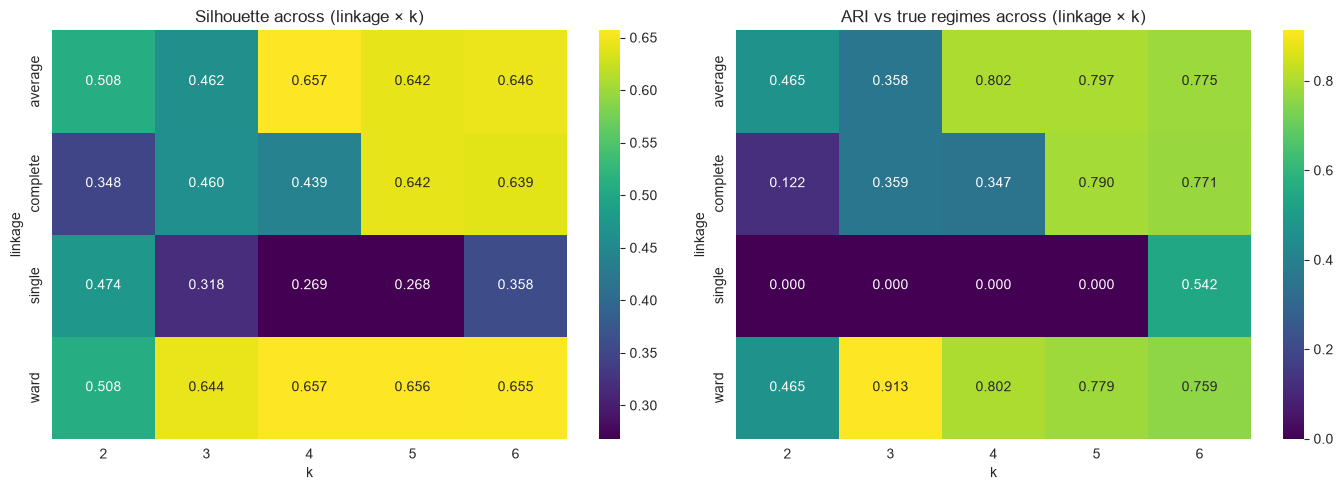

💡 How to read this grid:
   • The TRUE count is k=3 — the ward row should be at/near its best there (ARI ≈ 1)
   • Single linkage's best silhouette is NOT its best ARI: chaining can *look*
     cohesive while merging the wrong regimes — internal metrics alone can flatter
     the wrong geometry (the §3 lesson, now in numbers)
   • Complete/average trade some blob-shape fidelity for compactness — their k=3
     is respectable but rarely perfect on unequal spreads
   • Practical recipe: fix the geometry question FIRST (linkage), then choose the
     cut (k) — sweeping k under the wrong linkage optimizes the wrong model


In [15]:
# The other half of tuning: LINKAGE × k on the messy var_blobs data (truth known, synthetic)
linkage_grid = ["ward", "complete", "average", "single"]
k_grid_var = list(range(2, 7))

sil_rows, ari_rows = [], []
for lk_g in linkage_grid:
    for k_g in k_grid_var:
        ag_g = AgglomerativeClustering(n_clusters=k_g, linkage=lk_g).fit(X_var)
        sil_rows.append({"linkage": lk_g, "k": k_g,
                         "silhouette": silhouette_score(X_var, ag_g.labels_)})
        ari_rows.append({"linkage": lk_g, "k": k_g,
                         "ARI vs truth": adjusted_rand_score(y_var_true, ag_g.labels_)})

sil_pivot = pd.DataFrame(sil_rows).pivot(index="linkage", columns="k", values="silhouette")
ari_pivot = pd.DataFrame(ari_rows).pivot(index="linkage", columns="k", values="ARI vs truth")

print("Mean silhouette (higher = better):")
print(sil_pivot.round(3).to_string())
print("\nARI vs the three true regimes (1.0 = perfect):")
print(ari_pivot.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(sil_pivot, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("Silhouette across (linkage × k)")
sns.heatmap(ari_pivot, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("ARI vs true regimes across (linkage × k)")
plt.tight_layout()
plt.show()

print("💡 How to read this grid:")
print("   • The TRUE count is k=3 — the ward row should be at/near its best there (ARI ≈ 1)")
print("   • Single linkage's best silhouette is NOT its best ARI: chaining can *look*")
print("     cohesive while merging the wrong regimes — internal metrics alone can flatter")
print("     the wrong geometry (the §3 lesson, now in numbers)")
print("   • Complete/average trade some blob-shape fidelity for compactness — their k=3")
print("     is respectable but rarely perfect on unequal spreads")
print("   • Practical recipe: fix the geometry question FIRST (linkage), then choose the")
print("     cut (k) — sweeping k under the wrong linkage optimizes the wrong model")

---

## 8. Complete Hyperparameter Reference

### `AgglomerativeClustering` Parameters (scikit-learn 1.9, twin mirrors the core)

#### `n_clusters` (int or None, default=2) **[THE OUTPUT KNOB]**
- **Description**: number of clusters to stop the merging at. `None` is only legal with `distance_threshold` set — then the *height* decides k and this attribute reports what was found (`n_clusters_`)
- **Effect**:
  - **Too small**: distinct regimes merged (under-segmentation) — a forced coarse cut
  - **Too large**: real groups split into arbitrary fragments (over-segmentation)
  - **k = 1**: the root, one cluster, no information
  - **k = n−1 (max)**: nearly every point its own cluster — noise-magnifier
- **The key asymmetry vs K-Means**: `n_clusters` does NOT steer the fit — the tree is built once; this parameter (or a threshold) only selects **where to stop merging**. Changing k is a re-cut, not a re-fit (the twin does the same)
- **Typical range**: 2–15 for tabular segmentation
- **Tuning strategy**: silhouette sweep + merge-height gaps (§7) + domain logic
- **Example**: `AgglomerativeClustering(n_clusters=5, linkage='ward')`

---

#### `linkage` ({'ward', 'complete', 'average', 'single'}, default='ward') **[THE GEOMETRY KNOB]**
- **Description**: the rule defining "distance between two clusters" — which pair merges next
- **Effect (the four philosophies, §2)**:
  - **ward** (default): merge the pair minimizing within-cluster variance increase — blob-chasing, K-Means's closest cousin, needs euclidean metric
  - **complete**: farthest-member distance — compact, chain-resistant clusters
  - **average**: mean over all cross pairs — the robust compromise
  - **single**: closest-member distance — follows chains; traces non-convex shapes; fragile under noise
- **When to change**: misshapen or chaining partitions (§9's first recipe); elongated groups ward fragments; noisy data single snakes through
- **This is the decision with the largest effect on the partition** — bigger than any k sweep (§7's grid)
- **Example**: `AgglomerativeClustering(n_clusters=3, linkage='average')`

---

#### `metric` (str or callable, default='euclidean') **[sklearn only — twin is euclidean-fixed]**
- **Description**: the point-to-point distance the linkage consumes. Values: `'euclidean'`, `'l1'`, `'l2'`, `'manhattan'`, `'cosine'`, `'precomputed'` (pass a precomputed distance matrix to `fit`), or any callable
- **Constraint**: with `linkage='ward'` only `'euclidean'`/`'l2'` are accepted — ward is *defined* on variance, which needs euclidean geometry
- **Modern spelling**: `affinity=` was renamed to `metric=` (1.2) and is now **removed** — old tutorials with `affinity='manhattan'` raise `InvalidParameterError` at fit
- **When to change**: cosine for embedding/TF-IDF geometry; manhattan/l1 for outlier-robust or high-dim ordinal data; precomputed for domain-specific dissimilarities (e.g. sequence alignment scores)
- **Example**: `AgglomerativeClustering(n_clusters=4, linkage='average', metric='cosine')`

---

#### `distance_threshold` (float, default=None) **[sklearn only — the height-cut mode]**
- **Description**: merge only while the linkage distance stays *below* this threshold — clusters that would need a more expensive merge stay separate, so **k is discovered, not imposed**
- **Contract**: if set, `n_clusters` must be `None` and `compute_full_tree` must be `True` (the tree must exist down to the cut)
- **Effect**: `n_clusters_` reports the discovered count; the natural workflow is *read the dendrogram's gap → set the threshold just above it* (demonstrated in §6's extras cell)
- **Trade-off vs `n_clusters`**: threshold = "similarity budget" semantics (great when distance units are meaningful, e.g. phylogenetic or cosine); n_clusters = "how many buckets" semantics (great for business segmentation)
- **Example**: `AgglomerativeClustering(n_clusters=None, distance_threshold=7.5, compute_full_tree=True)`

---

#### `compute_full_tree` ('auto' or bool, default='auto') **[sklearn only]**
- **Description**: whether to build the tree past `n_clusters` or stop early. `'auto'` (verified 1.9 docstring) = `True` when `distance_threshold` is set **or** `n_clusters < max(100, 0.02·n_samples)`; otherwise `False` (early stop)
- **Effect**: early stopping is a speed optimization only — with a connectivity matrix and varying k it's usually worth building the full tree once (with `memory=` caching) and re-cutting
- **Twin**: always conceptually "full tree to n_clusters" — the twin has no tree at all
- **Example**: `AgglomerativeClustering(compute_full_tree=True)`

---

#### `compute_distances` (bool, default=False) **[sklearn only]**
- **Description**: compute and store `distances_` (the merge heights) even when no `distance_threshold` is used — the attribute dendrogram plotting needs
- **Cost**: a small computational/memory overhead; harmless at modest n
- **Example**: `AgglomerativeClustering(n_clusters=4, linkage='ward', compute_distances=True)`

---

#### `connectivity` (array-like / sparse / callable, default=None) **[sklearn only — out of twin scope]**
- **Description**: restrict legal merges to neighbors in a graph (e.g. `kneighbors_graph(X, n_neighbors=10)`), or a spatial adjacency structure. `None` = unconstrained
- **Effect**: structured/spatial clustering — clusters respect the data's graph, results are less blob-dependent, and big-n fits become tractable with sparse connectivity
- **Example**: `AgglomerativeClustering(n_clusters=8, connectivity=kneighbors_graph(X, 10, include_self=False))`

---

#### `memory` (str or joblib.Memory, default=None) **[sklearn only]**
- **Description**: cache the tree computation between fits — useful when you sweep `n_clusters` over the same data (the tree is identical; only the cut changes)
- **Example**: `AgglomerativeClustering(memory='./cache_dir')`

---

#### The scratch twin:
```python
from models.clustering_models import AgglomerativeClusteringScratch
AgglomerativeClusteringScratch(n_clusters=4, linkage='ward')
```
- **Two parameters only**: `n_clusters` (int, 1 ≤ k < n_samples) and `linkage` (the four classics)
- Fitted: `labels_`, `n_clusters_` — no `children_`/`distances_`, no `predict`
- **Euclidean only, no threshold mode, no connectivity** — those lives are sklearn/scipy's
- Fully deterministic: no `random_state` to pin, nothing to restart

### Parameter Combination Recipes

#### Clean blobs, unknown k (the everyday recipe):
```python
X_scaled = StandardScaler().fit_transform(X)
AgglomerativeClustering(n_clusters=k_from_silhouette, linkage='ward')
```

#### Let the tree choose k (height-cut mode):
```python
# 1) read the gap: dendrogram(linkage(X_scaled, method='ward'))
# 2) set the threshold just above the gap
AgglomerativeClustering(n_clusters=None, distance_threshold=gap_height,
                        compute_full_tree=True, linkage='ward')
```

#### Non-convex / connected structure (rings, moons, rivers):
```python
AgglomerativeClustering(n_clusters=2, linkage='single')   # + low noise data
```

#### Text / embeddings geometry:
```python
AgglomerativeClustering(n_clusters=6, linkage='average', metric='cosine')
```

#### Outlier-robust ordinal data:
```python
AgglomerativeClustering(n_clusters=5, linkage='complete', metric='manhattan')
```

#### Spatially structured data (large n made tractable):
```python
from sklearn.neighbors import kneighbors_graph
AgglomerativeClustering(n_clusters=8, linkage='ward',
                        connectivity=kneighbors_graph(X, 10, include_self=False))
```

#### The twin (study/read mode):
```python
AgglomerativeClusteringScratch(n_clusters=4, linkage='ward')   # labels_, n_clusters_
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Scale Features — before ward especially, always**
Euclidean distance (and ward's variance criterion) is directly scale-sensitive; this
is the same non-negotiable rule as K-Means/KNN (nb 07/12).
```python
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)
AgglomerativeClustering(n_clusters=4, linkage='ward').fit(X_scaled)
```
(The metric switch — `metric='cosine'` — does NOT remove the scaling duty for the
other features' geometry; cosine changes the ruler, not the unit chaos.)

---

#### 2. **Choose the Linkage Deliberately — it outranks every other decision**
```python
# default ward is right for compact blobs;
# switch when the geometry disagrees:
#   elongated groups fragmenting under ward → 'average' or 'complete'
#   noisy low-level structure chaining under 'single' → 'complete'/'ward'
#   connected structure (rings/moons/river networks) → 'single' + low noise
```
§3's bridge demo and §7's linkage×k grid are the two reference views for this call.

---

#### 3. **Triangulate k: Heights + Silhouette + Domain**
```python
Z = linkage(X_scaled, method='ward')                    # the tree
dendrogram(Z, truncate_mode='lastp', p=25)              # read the height gap
sils = [silhouette_score(X_scaled, AgglomerativeClustering(
           n_clusters=k, linkage='ward').fit_predict(X_scaled)) for k in range(2, 11)]
```
When the height gap, the silhouette peak, and a business-meaningful count agree — trust it.

---

#### 4. **Read the Dendrogram BEFORE Committing to a k**
The tree is the algorithm's full confession: short branches = confident structure,
tall sparse branches = suspicious minority/outliers, one dominant long stem = the
linkage chained the data. Two minutes of dendrogram reading beats any metric table.

---

#### 5. **Use `truncate_mode='lastp'` for Readable Big-n Dendrograms**
A 10k-leaf dendrogram is unreadable and slow to render:
```python
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
```
Each leaf becomes an aggregated bundle with its member count shown.

---

#### 6. **For n Beyond ~20k Rows — Change the Algorithm, Not the Grit**
The O(n²) matrix is a hard memory wall (~50k rows ≈ 20 GB float64). Reach for
`Birch` (hierarchical-flavored, memory-light), subsample then cluster, or the
linear-cost family (K-Means/MiniBatchKMeans, DBSCAN).

---

#### 7. **Profile Clusters Like Notebook 12 Taught**
```python
df["cluster"] = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
summary = df.groupby("cluster").mean().round(1)
```
A cluster nobody can describe in domain words is a geometric accident, not a segment.

---

#### 8. **Pin Your Expectations: Determinism Is Free Here**
No `random_state` exists — the same X yields the same tree forever. This makes
hierarchical clustering ideal for regression-testing pipelines and for "the report
must match last quarter's numbers" situations. (K-Means needs seeds for the same guarantee.)

---

### ❌ Common Mistakes

#### 1. **Feeding Unscaled Features** (the class #1 mistake, again)
```python
# BAD:  ward on [age (20-70), income (0-500k), spend (0-100)] → income owns the tree
# GOOD: StandardScaler first — every feature contributes per its variance, not its units
```

---

#### 2. **Single Linkage on Noisy/Sparse Data**
```python
# BAD: single linkage + real-world noise → one snake that swallowed the dataset
# GOOD: know WHY you chose single (connectedness geometry); else complete/average/ward
```
Chaining through noise is the most common "my clustering looks random" report in this family.

---

#### 3. **Assuming Labels Generalize to New Rows**
```python
# BAD:  model.predict(X_new)          → AttributeError: no such method — by design
# GOOD: refit KMeans with the same k and assign via centroids, or
#       nearest-member assignment: for each new row, nearest fitted point's label
```

---

#### 4. **Using `affinity=` from Old Tutorials**
```python
# BAD:  AgglomerativeClustering(affinity='manhattan')   → InvalidParameterError (removed)
# GOOD: AgglomerativeClustering(metric='manhattan', linkage='complete')
```
(And remember: `linkage='ward'` accepts only euclidean/l2 — pairing ward with a
non-euclidean metric raises at fit time.)

---

#### 5. **Comparing Dendrogram Heights Across Linkages or Metrics**
A height of "6" under ward (variance units) and "6" under single (plain distance) are
different currencies. Read one tree at a time; compare PARTITIONS (silhouette/ARI), not heights.

---

#### 6. **Treating `n_clusters` as a Fitting Knob**
Unlike K-Means, k does not guide the tree — it only selects the stop level. Sweeping
`n_clusters` and re-fitting from scratch each time wastes the model's whole selling
point: build once, cut many times (§7).

---

#### 7. **Ignoring the Late-Merging Outlier Branches**
The dendrogram hands you outlier candidates for free: branches that stay singletons
until very tall junctions. DBSCAN would label them -1; here, read and treat them manually.

---

#### 8. **Expecting Silhouette Alone to Pick the Right Geometry**
Silhouette ranks cuts *within* a fixed linkage; across linkages a cohesive-but-wrong
chained partition can out-score the true one (§7's grid shows it). Internal metrics
grade compactness, not correctness.

---

### Evaluation Cheat-Sheet (Unsupervised Edition — same tools as nb 12)

| Metric | Needs y? | Range | Direction | Notes |
|---|---|---|---|---|
| **Silhouette** | no | [-1, 1] | higher = better | the cut-point advisor; supports per-sample diagnostics |
| **Davies-Bouldin** | no | [0, ∞) | lower = better | ratio of within/between scatter |
| **Calinski-Harabasz** | no | [0, ∞) | higher = better | fast; ratio (between/within) |
| **Merge-height gap** | no | — | bigger gap = more natural cut | the dendrogram's own advice |
| **ARI** | **yes** (or two engines) | [-1, 1] | 1 = identical partitions | truth-checks (synthetic) or engine-agreement |

---

### Debugging Recipes

#### Single Linkage Returns One Snake + Singletons?
1. That *is* single linkage under noise — switch to complete/average/ward
2. If you NEED connectedness geometry: denoise first (outlier removal, smoothing) or reduce dimensionality
3. Inspect the dendrogram: a long single stem = chained tree; many short stems = healthy

#### Ward Fragments an Obvious Elongated Group?
1. Ward's variance criterion prefers compact similar-size blobs — try `linkage='average'`
2. Or whiten with PCA (nb 15) so the elongated direction becomes a clean axis
3. Or accept k larger than "true" and merge clusters post-hoc by profile similarity

#### Clusters Disagree With Domain Knowledge?
1. Check scaling first (one dominant feature owns the tree)
2. Drop irrelevant dimensions — noisy features blur all merges
3. Try `metric='cosine'` if the data lives on direction/angle geometry (embeddings, TF-IDF)
4. Read the dendrogram around the disagreement: which merge joined the wrong things, and at what height?

#### Dendrogram Unreadable (n Large)?
1. `truncate_mode='lastp', p=25..30`
2. Or fit on a subsample to explore, then fit the full data at the chosen k
3. Or skip the plot: `fcluster(Z, t=k, criterion='maxclust')` answers "labels now" directly

#### MemoryError / Effectively Hung at Big n?
1. The O(n²) wall — subsample or switch to `Birch`
2. For massive n: MiniBatchKMeans, DBSCAN (HNSW-backed variants), or a two-stage pipeline (Birch → agglomerative on subcluster centers)

#### Need Labels for New Rows After All?
1. Refit `KMeans` with the same k and use its `.predict()` (fast, centroid-based)
2. Or assign each new row the label of its nearest *fitted point* (1-NN against the fitted rows — exact for single/average intuition, approximate for ward)
3. Or re-fit agglomerative on data + new rows (fine at small n — the tree rebuilds in seconds)

---

## 10. Real-world Examples

Two examples chosen as a **pair of opposites**:

- **Example 1 — Iris (sklearn-bundled real data, 150 flowers × 4 measurements)**: the
  classic taxonomy read. A real dataset, modest n, and a dendrogram that *ranks* how
  different the three species are. The workflow: scale → ward dendrogram → cut at
  k=2 and k=3 → crosstab + ARI against the species labels.
- **Example 2 — Nested customer segments (synthetic, deterministic)**: the case only
  hierarchical clustering can solve *as a question*. Six sub-personas nest inside
  three macro segments; the dendrogram shows the nesting explicitly, which no flat
  algorithm (K-Means at any k) can exhibit.

### Example 1: Iris — Reading a Real Taxonomy from a Dendrogram

The Wisconsin iris data: 150 samples (setosa / versicolor / virginica), 4 numeric
features (sepal & petal length/width). We pretend species labels don't exist, build
the tree, and let the dendrogram rank the groups.

REAL-WORLD EXAMPLE 1: IRIS TAXONOMY (WARD)

📊 Dataset: 150 flowers × 4 measurements
  (species labels exist but stay hidden until the external check)


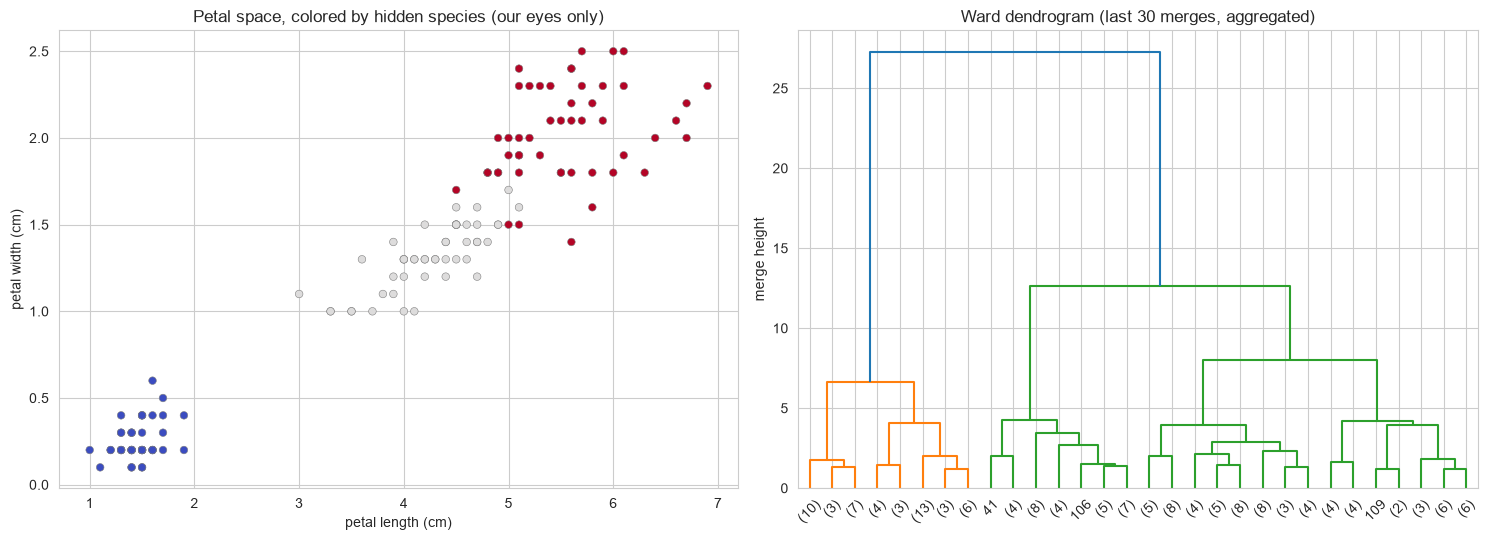

📊 The most expensive merges (the tree's top decisions):
 clusters left after | merge height
                   4 |        6.608
                   3 |        8.005
                   2 |       12.637
                   1 |       27.250

💡 Read the top junctions: the root split (→ 1 cluster) is the most expensive
   merge of the tree, and the junction right below it (→ 2 clusters) is the
   second most expensive. Those two heights ARE the biological story: one species
   sits far from the other two, and the remaining two are close cousins.


In [16]:
# Example 1 — iris: scale, build the ward tree, read the heights
iris_bundled = load_iris()
X_iris, y_iris = iris_bundled.data, iris_bundled.target       # truth used ONLY below

X_iris_scaled = StandardScaler().fit_transform(X_iris)

Z_iris = linkage(X_iris_scaled, method="ward")

print("=" * 60)
print("REAL-WORLD EXAMPLE 1: IRIS TAXONOMY (WARD)")
print("=" * 60)
print(f"\n📊 Dataset: {X_iris.shape[0]} flowers × {X_iris.shape[1]} measurements")
print(f"  (species labels exist but stay hidden until the external check)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# the classic discriminative feature view: petal length × petal width
axes[0].scatter(X_iris[:, 2], X_iris[:, 3], c=y_iris, cmap="coolwarm",
                s=30, edgecolors="gray", linewidths=0.4)
axes[0].set_xlabel("petal length (cm)"); axes[0].set_ylabel("petal width (cm)")
axes[0].set_title("Petal space, colored by hidden species (our eyes only)")

dendrogram(Z_iris, ax=axes[1], truncate_mode="lastp", p=30, show_leaf_counts=True)
axes[1].set_title("Ward dendrogram (last 30 merges, aggregated)")
axes[1].set_ylabel("merge height")

plt.tight_layout()
plt.show()

print("📊 The most expensive merges (the tree's top decisions):")
print(f"{'clusters left after':>20s} | {'merge height':>12s}")
for r in range(len(Z_iris) - 4, len(Z_iris)):
    print(f"{len(X_iris) - (r + 1):20d} | {Z_iris[r, 2]:12.3f}")

print("\n💡 Read the top junctions: the root split (→ 1 cluster) is the most expensive")
print("   merge of the tree, and the junction right below it (→ 2 clusters) is the")
print("   second most expensive. Those two heights ARE the biological story: one species")
print("   sits far from the other two, and the remaining two are close cousins.")

IRIS: CUT AT k=3 — CLUSTER × SPECIES
true species   setosa  versicolor  virginica
found cluster                               
0                   0          23         48
1                  49           0          0
2                   1          27          2

ARI(ward k=3, species) = 0.6153

IRIS: CUT AT k=2 — THE ROOT SPLIT
true species   setosa  versicolor  virginica
found cluster                               
0                   1          50         50
1                  49           0          0

ARI(ward k=2, species) = 0.5438


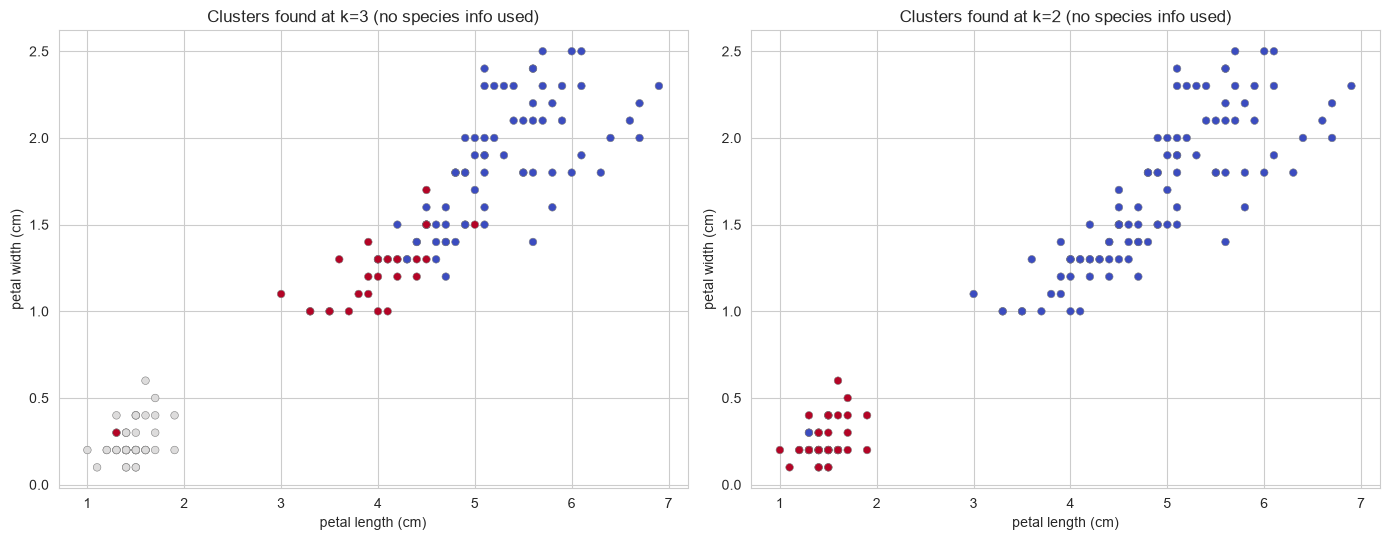

💡 The two cuts tell two honest stories from ONE tree:
   • k=3 approaches the species partition — with a handful of boundary mistakes
     where versicolor and virginica genuinely overlap (the tree admits no perfect answer)
   • k=2 is the tree's own 'first draft': the root split separates the clearly
     different group from everyone else — a coarser but fully defensible reading
   • No re-fit happened between the two panels: same tree, different cut.


In [17]:
# Cut the tree at k=3 (the species count) and k=2 (the root split) — then compare
ward3_iris = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_iris_scaled)
ward2_iris = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_iris_scaled)

species_names = [iris_bundled.target_names[t] for t in y_iris]

print("=" * 60)
print("IRIS: CUT AT k=3 — CLUSTER × SPECIES")
print("=" * 60)
crosstab3 = pd.crosstab(pd.Series(ward3_iris.labels_, name="found cluster"),
                        pd.Series(species_names, name="true species"))
print(crosstab3.to_string())
ari3 = adjusted_rand_score(y_iris, ward3_iris.labels_)
print(f"\nARI(ward k=3, species) = {ari3:.4f}")

print("\n" + "=" * 60)
print("IRIS: CUT AT k=2 — THE ROOT SPLIT")
print("=" * 60)
crosstab2 = pd.crosstab(pd.Series(ward2_iris.labels_, name="found cluster"),
                        pd.Series(species_names, name="true species"))
print(crosstab2.to_string())
ari2 = adjusted_rand_score(y_iris, ward2_iris.labels_)
print(f"\nARI(ward k=2, species) = {ari2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (labels_n, k_used) in zip(axes, [(ward3_iris.labels_, 3), (ward2_iris.labels_, 2)]):
    ax.scatter(X_iris[:, 2], X_iris[:, 3], c=labels_n, cmap="coolwarm",
               s=30, edgecolors="gray", linewidths=0.4)
    ax.set_xlabel("petal length (cm)"); ax.set_ylabel("petal width (cm)")
    ax.set_title(f"Clusters found at k={k_used} (no species info used)")

plt.tight_layout()
plt.show()

print("💡 The two cuts tell two honest stories from ONE tree:")
print("   • k=3 approaches the species partition — with a handful of boundary mistakes")
print("     where versicolor and virginica genuinely overlap (the tree admits no perfect answer)")
print("   • k=2 is the tree's own 'first draft': the root split separates the clearly")
print("     different group from everyone else — a coarser but fully defensible reading")
print("   • No re-fit happened between the two panels: same tree, different cut.")

### Example 2: Nested Segments — The Question Only a Hierarchy Can Answer

The unique selling point, made concrete. A retail dataset with **three macro
segments**, each containing **two genuine sub-personas** (6 groups in truth). A flat
algorithm — K-Means at k=3 or k=6 — can find either level. Only the dendrogram
*shows that the two levels are the same structure*: the evidence that the sub-personas
nest inside the macros is the shape of the tree itself.

REAL-WORLD EXAMPLE 2: NESTED SEGMENTS

📊 Simulated dataset: 300 customers × 3 features (age, income k$, spending score)
  Truth: 3 macro segments × 2 sub-personas each = 6 groups


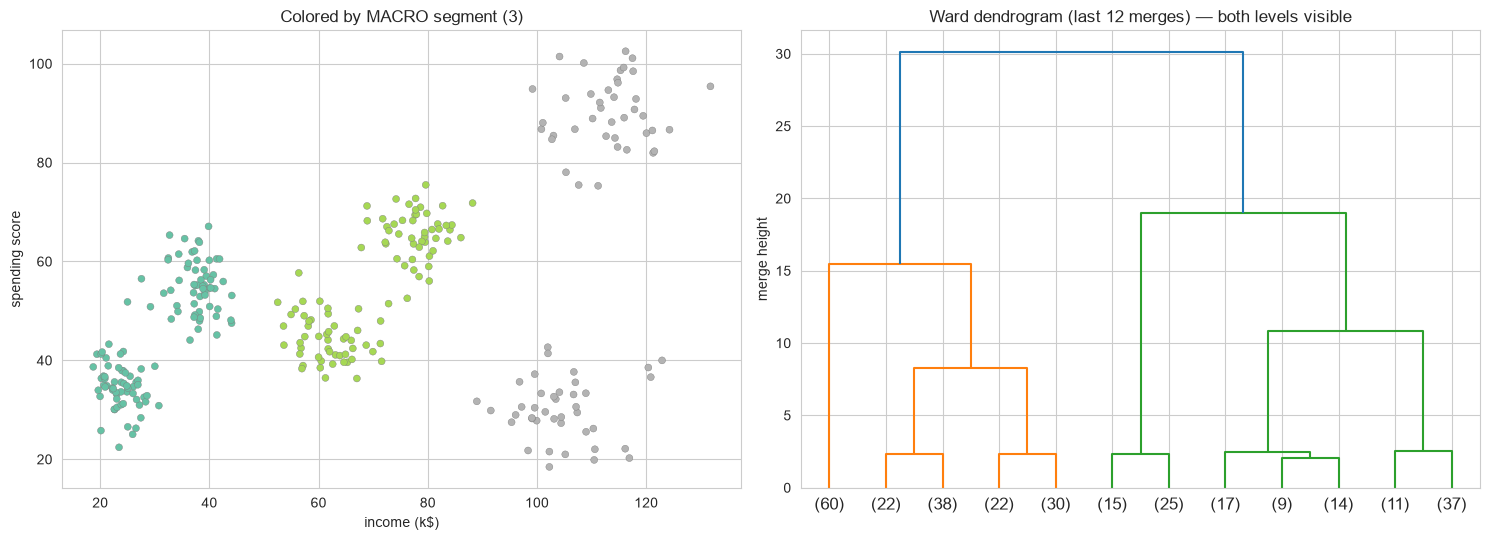

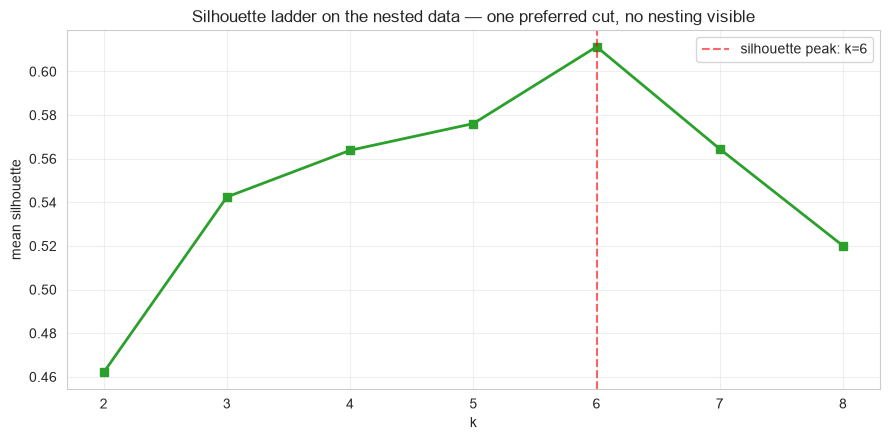

📊 Silhouette by k: k=2:0.462, k=3:0.542, k=4:0.564, k=5:0.576, k=6:0.611, k=7:0.564, k=8:0.520

💡 The silhouette ladder ranks FLAT cuts — its peak is one number, one answer.
   The dendrogram above is richer: two tiers of junction heights, macros first
   (tall), sub-personas below (short). That two-tier shape is the EVIDENCE of
   nesting — a quantity no flat algorithm's output can express.


In [18]:
# Build the nested dataset: 3 macro segments × 2 sub-personas each (deterministic)
rng_nested = np.random.default_rng(7)

SUBS = [
    ("young browsers",       [23, 24, 35],  [2.5, 3.0, 5.0], 60),
    ("senior browsers",      [34, 38, 55],  [3.0, 4.0, 6.0], 60),
    ("regular deal hunters", [42, 62, 45],  [3.0, 5.0, 5.0], 50),
    ("extreme couponers",    [48, 78, 65],  [4.0, 6.0, 6.0], 50),
    ("low-spend loyalists",  [55, 105, 30], [4.0, 8.0, 5.0], 40),
    ("high-spend loyalists", [45, 115, 90], [4.0, 8.0, 7.0], 40),
]
MACRO_OF_SUB = [0, 0, 1, 1, 2, 2]      # each macro segment = two consecutive sub-personas
MACRO_NAMES = ["value seekers", "mid-market", "premium"]

rows, y_micro, y_macro = [], [], []
for sub_id, (name, center, sigma, n) in enumerate(SUBS):
    rows.append(rng_nested.normal(center, sigma, size=(n, 3)))
    y_micro.extend([sub_id] * n)
    y_macro.extend([MACRO_OF_SUB[sub_id]] * n)

X_nested = np.vstack(rows)
y_micro = np.array(y_micro)
y_macro = np.array(y_macro)
X_nested_scaled = StandardScaler().fit_transform(X_nested)

print("=" * 60)
print("REAL-WORLD EXAMPLE 2: NESTED SEGMENTS")
print("=" * 60)
print(f"\n📊 Simulated dataset: {len(X_nested)} customers × 3 features "
      f"(age, income k$, spending score)")
print(f"  Truth: 3 macro segments × 2 sub-personas each = {len(SUBS)} groups")

Z_nested = linkage(X_nested_scaled, method="ward")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(X_nested[:, 1], X_nested[:, 2], c=y_macro, cmap="Set2",
                s=25, edgecolors="gray", linewidths=0.3)
axes[0].set_xlabel("income (k$)"); axes[0].set_ylabel("spending score")
axes[0].set_title("Colored by MACRO segment (3)")

dendrogram(Z_nested, ax=axes[1], truncate_mode="lastp", p=12, show_leaf_counts=True)
axes[1].set_title("Ward dendrogram (last 12 merges) — both levels visible")
axes[1].set_ylabel("merge height")

plt.tight_layout()
plt.show()

# silhouette ladder: what the internal metric prefers — and what it CANNOT see
ks_nested = list(range(2, 9))
sils_nested = []
for k_n in ks_nested:
    ag_n = AgglomerativeClustering(n_clusters=k_n, linkage="ward").fit(X_nested_scaled)
    sils_nested.append(silhouette_score(X_nested_scaled, ag_n.labels_))
best_k_nested = ks_nested[int(np.argmax(sils_nested))]

plt.figure(figsize=(9, 4.5))
plt.plot(ks_nested, sils_nested, "s-", lw=2, color="#2ca02c")
plt.axvline(x=best_k_nested, color="red", ls="--", alpha=0.6,
            label=f"silhouette peak: k={best_k_nested}")
plt.xlabel("k"); plt.ylabel("mean silhouette")
plt.title("Silhouette ladder on the nested data — one preferred cut, no nesting visible")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"📊 Silhouette by k: " + ", ".join(f"k={k}:{s:.3f}" for k, s in zip(ks_nested, sils_nested)))
print(f"\n💡 The silhouette ladder ranks FLAT cuts — its peak is one number, one answer.")
print("   The dendrogram above is richer: two tiers of junction heights, macros first")
print("   (tall), sub-personas below (short). That two-tier shape is the EVIDENCE of")
print("   nesting — a quantity no flat algorithm's output can express.")

CUT BOTH LEVELS: HIERARCHICAL vs K-MEANS (same scaled data)

  ARI vs MACRO truth (3 groups):
    hierarchical @ k=3 : 0.4281
    k-means     @ k=3 : 0.4343
  ARI vs MICRO truth (6 sub-personas):
    hierarchical @ k=6 : 0.9844
    k-means     @ k=6 : 0.9755

📊 The six sub-personas the tree resolves (and the macro above them):
                      count  avg_age  avg_income  avg_spend  macro segment
sub-persona                                                               
extreme couponers        50     46.8        77.8       65.4     mid-market
high-spend loyalists     40     44.7       113.0       90.0        premium
low-spend loyalists      40     55.8       104.5       30.0        premium
regular deal hunters     50     40.7        61.6       44.3     mid-market
senior browsers          60     34.1        37.5       55.0  value seekers
young browsers           60     22.1        23.8       34.5  value seekers


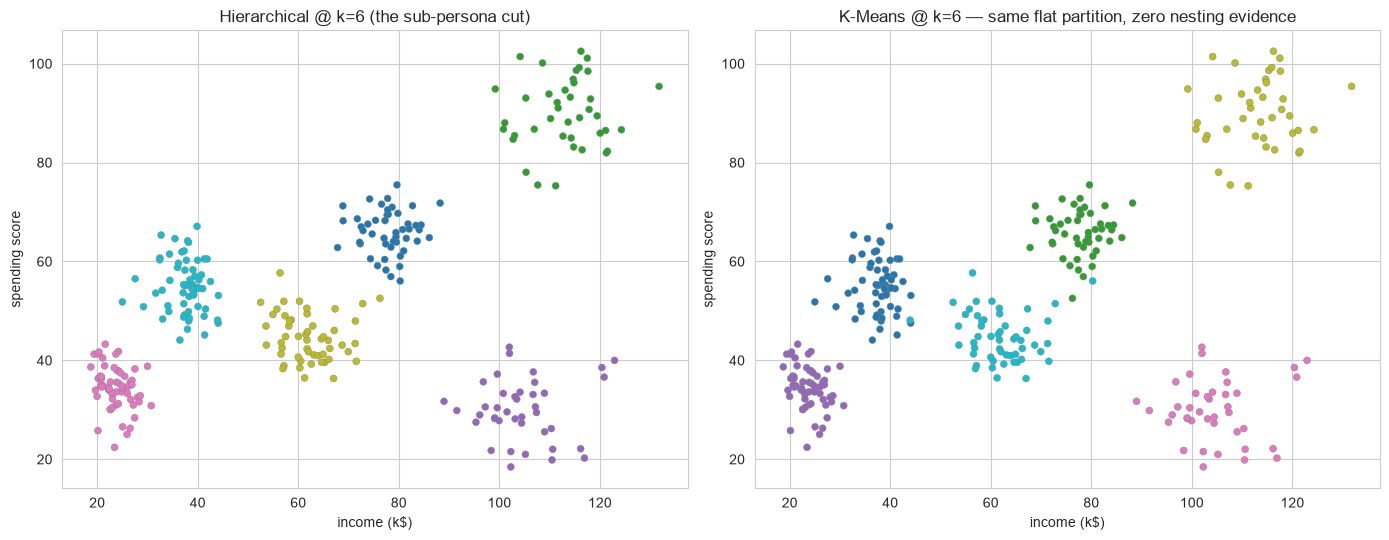


💡 Read the ARI block honestly: at each count, K-Means and hierarchical land on
   similar-quality partitions — flat machinery recovers flat levels fine.
   What K-Means CANNOT deliver: the dendrogram's two-tier structure, which tells
   you the 6 sub-personas are not six arbitrary buckets but pairs nested inside
   3 real segments. When the deliverable is a taxonomy (or a defensible 'we chose
   k because the tree shows two real levels'), the hierarchy is the product.


In [19]:
# Cut both levels; compare with K-Means at both counts — same partitions, different artifacts
ward3_n = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_nested_scaled)
ward6_n = AgglomerativeClustering(n_clusters=6, linkage="ward").fit(X_nested_scaled)
km3_n = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_nested_scaled)
km6_n = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X_nested_scaled)

print("=" * 66)
print("CUT BOTH LEVELS: HIERARCHICAL vs K-MEANS (same scaled data)")
print("=" * 66)
print(f"\n  ARI vs MACRO truth (3 groups):")
print(f"    hierarchical @ k=3 : {adjusted_rand_score(y_macro, ward3_n.labels_):.4f}")
print(f"    k-means     @ k=3 : {adjusted_rand_score(y_macro, km3_n.labels_):.4f}")
print(f"  ARI vs MICRO truth (6 sub-personas):")
print(f"    hierarchical @ k=6 : {adjusted_rand_score(y_micro, ward6_n.labels_):.4f}")
print(f"    k-means     @ k=6 : {adjusted_rand_score(y_micro, km6_n.labels_):.4f}")

# Profile the six sub-personas — the deliverable table
df_nested = pd.DataFrame(X_nested, columns=["age", "income (k$)", "spending score"])
df_nested["sub-persona"] = [SUBS[s][0] for s in y_micro]
profile_nested = df_nested.groupby("sub-persona").agg(
    count=("sub-persona", "size"),
    avg_age=("age", "mean"),
    avg_income=("income (k$)", "mean"),
    avg_spend=("spending score", "mean"),
).round(1)
print("\n📊 The six sub-personas the tree resolves (and the macro above them):")
sub_name_to_macro = {name: MACRO_NAMES[MACRO_OF_SUB[i]] for i, (name, _, _, _) in enumerate(SUBS)}
profile_nested["macro segment"] = profile_nested.index.map(sub_name_to_macro)
print(profile_nested.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X_nested[:, 1], X_nested[:, 2], c=ward6_n.labels_, cmap="tab10",
                s=25, edgecolors="gray", linewidths=0.3)
axes[0].set_xlabel("income (k$)"); axes[0].set_ylabel("spending score")
axes[0].set_title("Hierarchical @ k=6 (the sub-persona cut)")
axes[1].scatter(X_nested[:, 1], X_nested[:, 2], c=km6_n.labels_, cmap="tab10",
                s=25, edgecolors="gray", linewidths=0.3)
axes[1].set_xlabel("income (k$)"); axes[1].set_ylabel("spending score")
axes[1].set_title("K-Means @ k=6 — same flat partition, zero nesting evidence")

plt.tight_layout()
plt.show()

print("\n💡 Read the ARI block honestly: at each count, K-Means and hierarchical land on")
print("   similar-quality partitions — flat machinery recovers flat levels fine.")
print("   What K-Means CANNOT deliver: the dendrogram's two-tier structure, which tells")
print("   you the 6 sub-personas are not six arbitrary buckets but pairs nested inside")
print("   3 real segments. When the deliverable is a taxonomy (or a defensible 'we chose")
print("   k because the tree shows two real levels'), the hierarchy is the product.")

---

## 11. Comparison with Other Algorithms

### The Clustering Algorithm Field Guide (from the hierarchy's point of view)

| Aspect | **Hierarchical (agglomerative)** | K-Means | DBSCAN | GMM |
|---|---|---|---|---|
| **Need k upfront?** | the cut decides — but you still pass `n_clusters` | ✅ yes | ❌ no (discovered) | ✅ yes (`n_components`) |
| **Cluster shapes** | linkage-dependent (single → chains any shape; ward → compact blobs) | convex blobs only | **any shape** | ellipsoids |
| **Outlier handling** | must join a cluster (read tall singleton branches) | must join a cluster | **labels noise (-1)** | soft, no noise class |
| **Assignments** | hard | hard | hard | **soft (probabilities)** |
| **Predict for new rows** | ❌ (transduction only) | ✅ `.predict()` | ❌ | ✅ `.predict()` |
| **Randomness** | **none — deterministic** | seeds + restarts | none (ordering effects only) | seeds + init |
| **Cost** | O(n²) time & memory — the wall | O(n·k·m·i) — cheapest | O(n²) brute — heavy | EM — moderate |
| **Feature scaling** | **required** (ward doubly) | **required** | lenient-ish | **required** |
| **Hyperparams** | n_clusters, linkage, metric, threshold | k, init, n_init | eps, min_samples | n_components, covariance_type |
| **Worst enemy** | big n | non-convex shapes | varying density | too few samples |
| **Bonus sibling** | `Birch` for big-n hierarchical flavor | MiniBatchKMeans | HNSW variants | BayesianGaussianMixture |

### When to Choose Which

**Choose Hierarchical when…** n is modest, the *hierarchy/taxonomy* itself is the
product, k should be chosen after seeing the tree, or you need single-linkage
connectedness for non-convex structure.

**Choose K-Means when…** speed and scale matter, blobs are the truth, and new rows
must be assigned later.

**Choose DBSCAN when…** shapes are arbitrary, outliers must be flagged, or k is
unknown — and density is roughly uniform.

**Choose GMM when…** you need soft memberships, ellipsoidal clusters, or a
likelihood view (BIC model selection).

### Practical Comparison

In [20]:
# Head-to-head: five clusterers on two geometries — blobs (k=4) and rings (k=2)
def make_algorithms(k, dbscan_kwargs):
    return {
        "K-Means": KMeans(n_clusters=k, n_init=10, random_state=42),
        "Agglomerative (ward)": AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "Agglomerative (single)": AgglomerativeClustering(n_clusters=k, linkage="single"),
        "GMM": GaussianMixture(n_components=k, random_state=42),
        "DBSCAN": DBSCAN(**dbscan_kwargs),
    }

TASKS = {
    "blobs": dict(X=X_blobs, truth=y_true_blobs, k=4, dbscan=dict(eps=0.5, min_samples=5)),
    "rings": dict(X=X_rings, truth=y_rings, k=2, dbscan=dict(eps=0.2, min_samples=5)),
}

results_hc = {}
for data_name, task in TASKS.items():
    X_data, y_truth = task["X"], task["truth"]
    for name, algo in make_algorithms(task["k"], task["dbscan"]).items():
        t0 = time.time()
        if name == "GMM":
            algo.fit(X_data)
            labels_alg = algo.predict(X_data)
        else:
            labels_alg = algo.fit_predict(X_data)
        elapsed = time.time() - t0

        n_found = len(set(labels_alg)) - (1 if -1 in labels_alg else 0)
        mask = labels_alg != -1
        if len(set(labels_alg[mask])) >= 2:
            sil_val = silhouette_score(X_data[mask], labels_alg[mask])
        else:
            sil_val = np.nan

        results_hc[(data_name, name)] = {
            "labels": labels_alg,
            "ARI": adjusted_rand_score(y_truth, labels_alg),
            "silhouette": sil_val,
            "time_s": elapsed,
            "n_found": n_found,
        }

rows_hc = []
for (data_name, name), r in results_hc.items():
    rows_hc.append({
        "Dataset": data_name,
        "Algorithm": name,
        "Clusters found": r["n_found"],
        "Silhouette": round(r["silhouette"], 3) if not np.isnan(r["silhouette"]) else "n/a",
        "ARI vs truth": round(r["ARI"], 3),
        "Time (s)": round(r["time_s"], 3),
    })
df_hc = pd.DataFrame(rows_hc)

print("=" * 72)
print("ALGORITHM COMPARISON — BLOBS (k=4) vs RINGS (k=2)")
print("=" * 72)
print(df_hc.to_string(index=False))

print("\n💡 Reading the table:")
print("  • On BLOBS every engine recovers the four blobs — comparable quality")
print("  • On RINGS the geometry story inverts: K-Means, ward, and GMM slice by SECTOR")
print("    (ARI near 0) while single-linkage agglomerative and DBSCAN trace the rings")
print("  • This is notebook 12's comparison table with the missing column filled: the")
print("    single-linkage row is hierarchical clustering's superpower and its hazard")
print("  • DBSCAN was never told k, yet lands near the right count on both datasets")

ALGORITHM COMPARISON — BLOBS (k=4) vs RINGS (k=2)
Dataset              Algorithm  Clusters found  Silhouette  ARI vs truth  Time (s)
  blobs                K-Means               4       0.814         1.000     0.060
  blobs   Agglomerative (ward)               4       0.814         1.000     0.003
  blobs Agglomerative (single)               4       0.814         1.000     0.002
  blobs                    GMM               4       0.814         1.000     0.017
  blobs                 DBSCAN               5       0.702         0.772     0.007
  rings                K-Means               2       0.342        -0.002     0.033
  rings   Agglomerative (ward)               2       0.325        -0.001     0.003
  rings Agglomerative (single)               2       0.131         1.000     0.002
  rings                    GMM               2       0.333        -0.002     0.011
  rings                 DBSCAN               2       0.131         1.000     0.002

💡 Reading the table:
  • On BLOBS ev

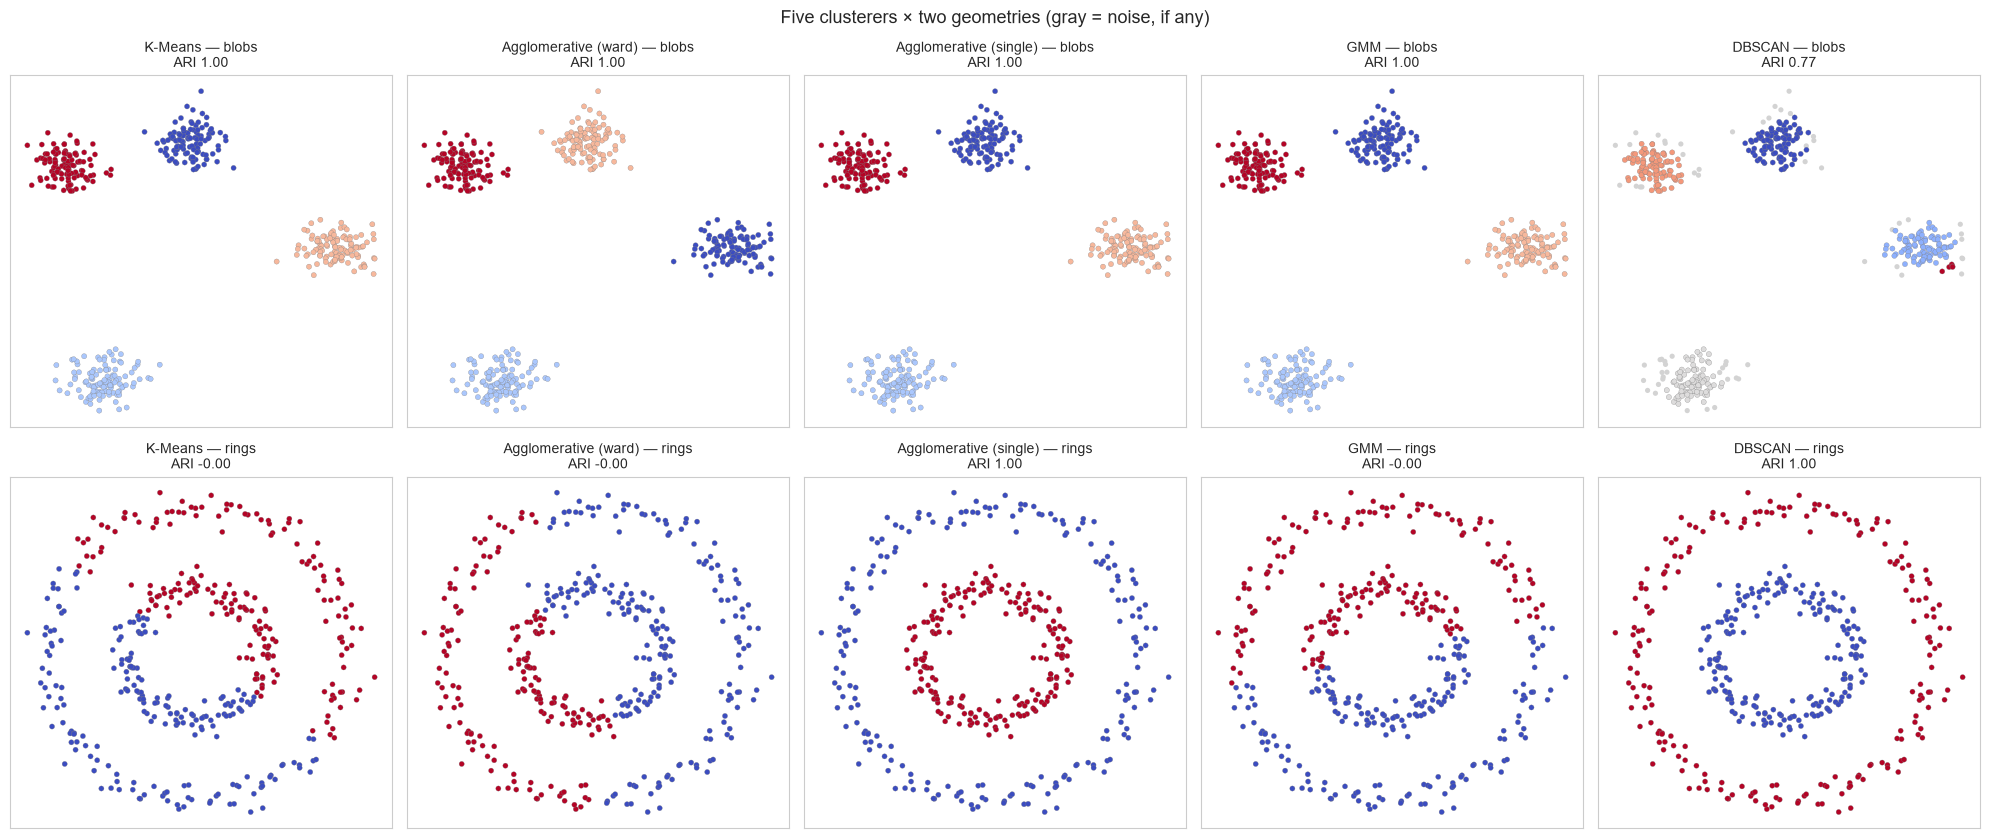


⚠️ One number never tells the story — silhouette flatters chained partitions;
   ARI needs truth, which real projects don't have. Budget a human review.

💡 Field notes for the hierarchy's row:
✅ Hierarchical (ward):
  • matches K-Means on convex blobs (same objective, different machinery)
  • the dendrogram is a deliverable in its own right; deterministic — no seeds
  • O(n²) memory: the first wall you hit as n grows
✅ Hierarchical (single):
  • traces connected structure (rings/moons) the other engines cannot express
  • chains across noise — the same property that makes it powerful (§3 vs §5)
  • treat it as a geometry choice, not a default


In [21]:
# Visualize all ten partitions: five algorithms × two geometries
algo_order = ["K-Means", "Agglomerative (ward)", "Agglomerative (single)", "GMM", "DBSCAN"]

fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for row, data_name in enumerate(["blobs", "rings"]):
    X_data = X_blobs if data_name == "blobs" else X_rings
    for col, name in enumerate(algo_order):
        r = results_hc[(data_name, name)]
        labels_alg = r["labels"]
        noise_mask = labels_alg == -1
        ax = axes[row, col]
        ax.scatter(X_data[noise_mask, 0], X_data[noise_mask, 1],
                   c="lightgray", s=14, edgecolors="none")
        ax.scatter(X_data[~noise_mask, 0], X_data[~noise_mask, 1],
                   c=labels_alg[~noise_mask], cmap="coolwarm",
                   s=14, edgecolors="gray", linewidths=0.2)
        ax.set_title(f"{name} — {data_name}\nARI {r['ARI']:.2f}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Five clusterers × two geometries (gray = noise, if any)", fontsize=13)
plt.tight_layout()
plt.show()

print("\n⚠️ One number never tells the story — silhouette flatters chained partitions;")
print("   ARI needs truth, which real projects don't have. Budget a human review.")
print("\n💡 Field notes for the hierarchy's row:")
print("✅ Hierarchical (ward):")
print("  • matches K-Means on convex blobs (same objective, different machinery)")
print("  • the dendrogram is a deliverable in its own right; deterministic — no seeds")
print("  • O(n²) memory: the first wall you hit as n grows")
print("✅ Hierarchical (single):")
print("  • traces connected structure (rings/moons) the other engines cannot express")
print("  • chains across noise — the same property that makes it powerful (§3 vs §5)")
print("  • treat it as a geometry choice, not a default")

---

## 12. References

### 📚 Academic Papers & Books

1. **Original Work**:
   - **Ward, J. H. (1963). "Hierarchical Grouping to Optimize an Objective Function."** *Journal of the American Statistical Association*, 58(301) — the variance criterion behind `linkage='ward'`
   - **Lance, G. N., & Williams, W. T. (1967). "A General Theory of Classificatory Sorting Strategies."** *The Computer Journal*, 9(4) — the update recurrences every implementation (including our twin) runs
   - Sneath, P. H. A., & Sokal, R. R. (1973). *Numerical Taxonomy.* W. H. Freeman — the codification of the field (UPGMA naming, linkage taxonomy)
2. **Modern Algorithmics**:
   - **Müllner, D. (2011). "Modern Hierarchical, Agglomerative Clustering Algorithms."** arXiv:1109.2378 — the nearest-neighbor-chain algorithm sklearn runs ($O(n^2)$ time), and the standard modern reference
   - Murtagh, F., & Contreras, P. (2012). "Algorithms for Hierarchical Clustering: An Overview." *WIREs Data Mining and Knowledge Discovery*, 2(1)
3. **Textbooks**:
   - Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, 2nd ed. (§14.3.12 — agglomerative clustering)
   - James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning* (2nd ed., Ch. 12 — unsupervised methods incl. hierarchical clustering)

### 🌐 Online Resources

- [Scikit-learn AgglomerativeClustering API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)
- [Scikit-learn Clustering User Guide — Hierarchical](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)
- [Scikit-learn Gallery: Plot Agglomerative Dendrogram](https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html) — the `children_`/`distances_` plotting pattern
- [Scikit-learn Gallery: Linkage Comparison](https://scikit-learn.org/stable/auto_examples/cluster/plot_linkage_comparison.html)
- [Scipy `cluster.hierarchy` Reference](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html) — `linkage`, `dendrogram`, `cut_tree`, `fcluster`
- [StatQuest: Hierarchical Clustering](https://www.youtube.com/watch?v=7xHsRkOdVwo)

### 📊 Key Concepts to Master

- **Agglomerative vs divisive**: bottom-up merging vs top-down splitting (DIANA) — agglomerative is what everyone ships
- **Linkage rules**: single (min), complete (max), average (mean), ward (variance increase) — the geometry knob
- **Ward's criterion**: $\Delta = \frac{n_A n_B}{n_A+n_B}\lVert\mu_A-\mu_B\rVert^2$ — the K-Means objective built from the bottom up
- **Lance–Williams recurrences**: exact distance updates from old distances + sizes; never re-measure
- **Dendrogram**: heights = merge distances; cutting = choosing k; the gap = natural structure
- **Irreversible greed**: merges never undo; bad early merges cascade
- **Transductive**: no `predict` — labels exist only for fitted rows (sklearn and twin agree)
- **No noise class**: every point joins a cluster (vs DBSCAN's -1)
- **Determinism**: no `random_state` — reproducibility for free
- **O(n²) wall**: memory caps n in the tens of thousands; `Birch`/subsample beyond
- **Internal vs external metrics**: silhouette/DB/CH need no truth; ARI only with trustworthy labels

### 🔗 Related Notebooks in this Repository

- `12_clustering_kmeans.ipynb` — the flat sibling: same unsupervised workflow, centroid machinery, `n_init` roulette vs this notebook's determinism
- `14_clustering_dbscan.ipynb` — the density sibling: discovers k, labels noise, arbitrary shapes
- `15_pca.ipynb` — whitening before clustering; distance concentration in high dims
- `02_logistic_regression.ipynb` — the supervised contrast: what changes when labels DO exist

### 📈 Evaluation Metrics

**Internal (no ground truth):**
- Silhouette (cohesion vs separation; the cut-point advisor), Davies-Bouldin (lower = better), Calinski-Harabasz (higher = better)
- Merge-height gaps — the dendrogram's own k advice

**External (only with trusted reference labels):**
- Adjusted Rand Index (chance-corrected, permutation-invariant) — also the engine-agreement metric (§6)
- Cluster × class crosstab — the order-free sanity table (§10)

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: agglomerative clustering builds a merge hierarchy — n singletons,
   greedy closest-pair merges, one tree; every partition is a cut of that tree
2. **Math**: four linkage rules define "closest pair"; Ward's criterion
   $\frac{n_A n_B}{n_A+n_B}\lVert\mu_A-\mu_B\rVert^2$ ties the method to K-Means's
   objective; Lance–Williams recurrences update all distances exactly, in $O(n)$ per merge
3. **Assumptions**: the linkage rule IS the geometry assumption; scaling is mandatory;
   labels are transductive; there is no noise class; O(n²) memory caps n
4. **Implementation**: the twin computes one squared-distance matrix, maintains
   Lance–Williams rows, merges greedily with deterministic tie-breaking, and — like
   sklearn — offers no `predict`; agreement with sklearn is exact (ARI = 1.0, all four linkages)
5. **Hyperparameters**: `linkage` is the geometry knob (the big decision), `n_clusters`
   (or `distance_threshold`) selects the cut, `metric`/`connectivity` are sklearn-only geometry upgrades
6. **Tuning**: silhouette sweep + merge-height gaps + domain sense triangulate k;
   sweep linkages before sweeping k — the wrong geometry makes every k answer the wrong question
7. **Practice**: iris (a real taxonomy read — root split, then the versicolor/virginica
   junction) and nested segments (the hierarchy's unique product: visible nesting that
   no flat algorithm can exhibit)

### When to Use Hierarchical Clustering

✅ **Use when**:
- the deliverable is a tree/taxonomy/nested segmentation (genes, documents, personas)
- k should be chosen from the data — one fit, every k visible
- n is modest (hundreds to ~20k rows) and determinism is a feature
- connected/non-convex structure matters and you can own single-linkage's hazards
- you need to *show* the grouping logic (dendrograms persuade stakeholders)

❌ **Avoid when**:
- n is large — the O(n²) matrix wall (use K-Means/MiniBatch, `Birch`, or subsample)
- new rows must be labeled post-fit (no `predict` — K-Means or 1-NN assignment instead)
- outliers must be flagged rather than absorbed (DBSCAN's -1)
- you need probabilistic memberships (GMM)
- single-linkage chaining would snake through your noise (and you need compactness)

### Best Practices Checklist

- ✅ **Scale features** (`StandardScaler`) — doubly true for ward
- ✅ **Choose the linkage deliberately** — geometry first, cut second (§3, §7)
- ✅ **Triangulate k**: merge-height gaps + silhouette + domain logic
- ✅ **Read the dendrogram** (`truncate_mode='lastp'` at big n) before trusting any table
- ✅ **Profile every cluster** (means table) and name it in domain words
- ✅ **Treat late-merging singletons as outlier candidates**
- ✅ **Use ARI** when comparing partitions across engines or against reference labels
- ✅ **Never call `predict`** — transductive; plan the new-row assignment pattern in advance
- ✅ **Beyond ~20k rows**: `Birch` / subsample / switch algorithms

### Critical Requirements

**1. Feature Scaling is MANDATORY:**
```python
X_scaled = StandardScaler().fit_transform(X)
```

**2. The Linkage Must Match the Geometry:**
- compact blobs → ward; elongated/diffuse → average/complete; connected structure → single

**3. Respect the Transductive Contract:**
- labels only for fitted rows; plan how unseen rows get assigned BEFORE deploying

### Advantages vs Disadvantages

**Advantages:**
- ✅ The full merge hierarchy — every k from one fit; nesting made visible
- ✅ Four linkages = four geometries from one implementation (incl. non-convex via single)
- ✅ Fully deterministic — no seeds, no restarts, no local-minimum roulette
- ✅ No learning-rate/convergence/diagnostics machinery — the loop terminates by construction
- ✅ The dendrogram is a stakeholder-legible artifact of the whole analysis

**Disadvantages:**
- ❌ O(n²) time and memory — the hard wall (Birch/subsample beyond)
- ❌ No `predict` — transductive only
- ❌ Greedy irreversible merges — early mistakes compound; no objective to restart against
- ❌ No noise/outlier label — contamination risk
- ❌ Linkage choice is a modeling decision with outsized consequences (and a real trap when made carelessly)

### The One-Quad: Hierarchical vs the Field

| Feature | Hierarchical | K-Means | DBSCAN | GMM |
|---|---|---|---|---|
| k decided post-fit (cut) | ✅ | ❌ | ✅ (discovered) | ❌ |
| non-convex shapes possible | ~ (single) | ❌ | ✅ | ~ (ellipses) |
| noise labels | ❌ | ❌ | ✅ | ❌ |
| predict new rows | ❌ | ✅ | ❌ | ✅ |
| deterministic | ✅ | seeds | ✅ | seeds |

### Unique Characteristic: One Fit, Every Answer

K-Means answers "given k, where are the groups?" and must be re-run per k.
Hierarchical clustering answers **"how do the groups nest?"** — and hands you *every*
partition simultaneously: cut at k=2, k=3, k=10; cut by height; cut by silhouette.
The tree is a compression of all clustering views of the dataset into one artifact —
which is why taxonomy-shaped problems (genes, documents, personas-inside-segments)
belong to this algorithm, and why "choosing k" here is a *reading* task, not a *search* task.

### Next Steps

1. **Practice**: take a personal dataset, scale it, and read the ward dendrogram before fitting anything flat — does the tree's two-tier structure match your domain?
2. **Diagnose**: reproduce the §3 bridge on your own data with all four linkages; the differences ARE your geometry
3. **Experiment**: `distance_threshold` mode on cosine-scaled text embeddings — k discovery by height
4. **Compare**: nb 12-style four-algorithm table on your data (add the single-linkage column — nb 12 couldn't)
5. **Read** notebooks 14 (DBSCAN — the noise specialist) and 15 (PCA — the high-dim fix)
6. **Reflect**: the dendrogram ranks every merge the algorithm almost made — which near-miss merges would have changed your story?

---

**Congratulations!** You can now build, read, cut, and defend a merge hierarchy — and you know that the linkage rule, not the algorithm, decides what your clusters mean. 🎯🎉

**Remember**: scale your features, choose the linkage like it's the model (it is), read the dendrogram before reading any metric — and never promise a customer new-row predictions from a transductive model!